# AgroVision FYP2: Enhanced Augmentation, Retraining and Retesting

This experiment investigates whether enhanced data augmentation improves model generalisation from PlantVillage to external field datasets.

## Experiment Objectives
1. Apply enhanced data augmentation to training images.
2. Retrain EfficientNetB0, ResNet50 and MobileNetV2.
3. Evaluate the retrained models on PlantVillage, PlantDoc and FieldPlant.
4. Compare the results with the original baseline.
5. Investigate possible dataset-related limitations.


In [1]:
# ============================================================
# AGROVISION FYP2 - ENHANCED AUGMENTATION EXPERIMENT
# SECTION 1.1: ENVIRONMENT AND GPU VERIFICATION
# ============================================================

import os
import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("=" * 60)
print("AGROVISION FYP2 - ENVIRONMENT VERIFICATION")
print("=" * 60)

print(f"Python version     : {sys.version.split()[0]}")
print(f"TensorFlow version : {tf.__version__}")
print(f"NumPy version      : {np.__version__}")
print(f"Pandas version     : {pd.__version__}")

gpus = tf.config.list_physical_devices("GPU")

print(f"Available GPUs     : {gpus}")

assert len(gpus) > 0, (
    "No GPU detected. Check your Colab runtime."
)

print("\nPASS: GPU environment verified.")
print("=" * 60)


AGROVISION FYP2 - ENVIRONMENT VERIFICATION
Python version     : 3.13.16
TensorFlow version : 2.21.0
NumPy version      : 2.4.6
Pandas version     : 2.2.3
Available GPUs     : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

PASS: GPU environment verified.


In [2]:
# ============================================================
# SECTION 1.2: EXPERIMENT CONFIGURATION
# ============================================================

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Dataset
IMAGE_SIZE = (160, 160)
IMAGE_CHANNELS = 3
NUM_CLASSES = 38

# Training
BATCH_SIZE = 32

# Models
MODEL_NAMES = [
    "EfficientNetB0",
    "ResNet50",
    "MobileNetV2"
]

# Existing Google Drive project folder
PROJECT_DIR = Path(
    "/content/drive/MyDrive/AgroVision_FYP2"
)

print("=" * 60)
print("EXPERIMENT CONFIGURATION")
print("=" * 60)

print(f"Random seed       : {SEED}")
print(f"Image size        : {IMAGE_SIZE}")
print(f"Number of classes : {NUM_CLASSES}")
print(f"Batch size        : {BATCH_SIZE}")
print(f"Models            : {MODEL_NAMES}")
print(f"Project directory : {PROJECT_DIR}")

print("\nPASS: Experiment configuration completed.")
print("=" * 60)


EXPERIMENT CONFIGURATION
Random seed       : 42
Image size        : (160, 160)
Number of classes : 38
Batch size        : 32
Models            : ['EfficientNetB0', 'ResNet50', 'MobileNetV2']
Project directory : /content/drive/MyDrive/AgroVision_FYP2

PASS: Experiment configuration completed.


In [3]:
# ============================================================
# SECTION 1.3: GOOGLE DRIVE AND DATASET FILE VERIFICATION
# ============================================================

import json
from google.colab import drive

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Locate the existing Phase 2 preparation folder
PV_PREP_DIR = PROJECT_DIR / "plantvillage_preparation"

# 3. Define required preparation files
required_files = {
    "Final split manifest":
        PV_PREP_DIR / "final_split_manifest.csv",

    "Class-to-index mapping":
        PV_PREP_DIR / "class_to_index.json",

    "Training class weights":
        PV_PREP_DIR / "class_weights.json",

    "Preprocessing plan":
        PV_PREP_DIR / "preprocessing_augmentation_plan.json"
}

print("=" * 60)
print("AGROVISION FYP2 - DATASET FILE VERIFICATION")
print("=" * 60)

# 4. Verify file availability
missing_files = []

for name, filepath in required_files.items():
    if filepath.is_file():
        print(f"{name}: FOUND")
    else:
        print(f"{name}: MISSING")
        missing_files.append(str(filepath))

assert not missing_files, (
    "Required files are missing:\n"
    + "\n".join(missing_files)
)

# 5. Load the existing split manifest
manifest_df = pd.read_csv(
    required_files["Final split manifest"]
)

# 6. Verify dataset distribution
expected_splits = {
    "train": 37978,
    "validation": 8155,
    "test": 8151
}

actual_splits = manifest_df["split"].value_counts()

print("\nDataset split distribution:")

for split_name, expected in expected_splits.items():
    actual = int(actual_splits.get(split_name, 0))
    print(f"{split_name}: {actual:,} images")
    assert actual == expected, (
        f"Unexpected {split_name} image count."
    )

assert len(manifest_df) == 54284
assert manifest_df["plantvillage_class"].nunique() == NUM_CLASSES

print("\nTotal images:", len(manifest_df))
print("Number of classes:", NUM_CLASSES)

print("\nPASS: Phase 2 dataset files verified.")
print("=" * 60)


Mounted at /content/drive
AGROVISION FYP2 - DATASET FILE VERIFICATION
Final split manifest: FOUND
Class-to-index mapping: FOUND
Training class weights: FOUND
Preprocessing plan: FOUND

Dataset split distribution:
train: 37,978 images
validation: 8,155 images
test: 8,151 images

Total images: 54284
Number of classes: 38

PASS: Phase 2 dataset files verified.


In [4]:
# ============================================================
# SECTION 1.4: RESTORE PLANTVILLAGE IMAGE DATASET
# ============================================================

import kagglehub

print("=" * 60)
print("AGROVISION FYP2 - RESTORE PLANTVILLAGE DATASET")
print("=" * 60)

# 1. Restore the original PlantVillage dataset
plantvillage_path = Path(
    kagglehub.dataset_download(
        "aftaabahmedshaik/plantvillage-dataset"
    )
)

plantvillage_color_path = plantvillage_path / "color"

assert plantvillage_color_path.is_dir(), (
    "PlantVillage colour directory not found."
)

print("\nDataset root:", plantvillage_path)
print("Colour images:", plantvillage_color_path)

# 2. Verify the original 38 class folders
class_folders = sorted(
    p.name
    for p in plantvillage_color_path.iterdir()
    if p.is_dir()
)

expected_classes = set(
    manifest_df["plantvillage_class"].unique()
)

assert set(class_folders) == expected_classes, (
    "Dataset class folders do not match the manifest."
)

print("\nClass folders found:", len(class_folders))

# 3. Resolve the original Kaggle image paths
OLD_ROOT = Path("/kaggle/input/plantvillage-dataset/color")
NEW_ROOT = plantvillage_color_path

training_manifest = manifest_df.copy()

def resolve_image_path(original_path):
    relative_path = Path(original_path).relative_to(OLD_ROOT)
    return str(NEW_ROOT / relative_path)

training_manifest["resolved_filepath"] = (
    training_manifest["filepath"].apply(resolve_image_path)
)

# 4. Check sample images from every split
print("\nSample image accessibility:")

for split_name in ["train", "validation", "test"]:
    sample_paths = training_manifest.loc[
        training_manifest["split"] == split_name,
        "resolved_filepath"
    ].head(5)

    accessible = sum(
        Path(path).is_file()
        for path in sample_paths
    )

    print(f"{split_name}: {accessible}/5 accessible")

    assert accessible == 5, (
        f"Missing sample images in {split_name} split."
    )

print("\nTotal manifest records:", len(training_manifest))

print("\nPASS: PlantVillage dataset restored successfully.")
print("=" * 60)


AGROVISION FYP2 - RESTORE PLANTVILLAGE DATASET


100%|██████████| 816M/816M [00:21<00:00, 39.7MB/s] 

Extracting files...



Dataset root: /root/.cache/kagglehub/datasets/aftaabahmedshaik/plantvillage-dataset/versions/1
Colour images: /root/.cache/kagglehub/datasets/aftaabahmedshaik/plantvillage-dataset/versions/1/color

Class folders found: 38

Sample image accessibility:
train: 5/5 accessible
validation: 5/5 accessible
test: 5/5 accessible

Total manifest records: 54284

PASS: PlantVillage dataset restored successfully.


In [5]:
# ============================================================
# SECTION 1.5: PREPARE TENSORFLOW DATA PIPELINES
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - TENSORFLOW DATA PIPELINES")
print("=" * 60)

# 1. Load original class-to-index mapping
with open(required_files["Class-to-index mapping"], "r") as f:
    class_to_index = json.load(f)

assert len(class_to_index) == NUM_CLASSES
assert set(class_to_index.values()) == set(range(NUM_CLASSES))

# 2. Prepare numerical labels
dataset_df = training_manifest.copy()

dataset_df["label"] = (
    dataset_df["plantvillage_class"].map(class_to_index)
)

assert dataset_df["label"].notna().all()
dataset_df["label"] = dataset_df["label"].astype("int32")

# 3. Verify all image paths (not just samples)
file_exists = dataset_df["resolved_filepath"].map(
    lambda path: Path(path).is_file()
)

assert file_exists.all(), (
    f"{(~file_exists).sum()} image files are missing."
)

print(f"Accessible images: {file_exists.sum():,}")

# 4. Restore original dataset splits
train_data = dataset_df[
    dataset_df["split"] == "train"
].copy().reset_index(drop=True)

val_data = dataset_df[
    dataset_df["split"] == "validation"
].copy().reset_index(drop=True)

test_data = dataset_df[
    dataset_df["split"] == "test"
].copy().reset_index(drop=True)

# 5. Define image loading and preprocessing
def load_and_preprocess_image(filepath, label):

    image_bytes = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMAGE_SIZE,
        method="bilinear"
    )

    image = tf.cast(image, tf.float32)
    label = tf.cast(label, tf.int32)

    return image, label

# 6. Build TensorFlow datasets
AUTOTUNE = tf.data.AUTOTUNE

def create_dataset(dataframe, training=False):

    paths = dataframe[
        "resolved_filepath"
    ].astype(str).to_numpy()

    labels = dataframe[
        "label"
    ].to_numpy(dtype="int32")

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

# 7. Create three datasets
train_ds = create_dataset(train_data, training=True)
val_ds = create_dataset(val_data, training=False)
test_ds = create_dataset(test_data, training=False)

# 8. Verify a sample training batch
batch_images, batch_labels = next(iter(train_ds))

assert batch_images.shape == (32, 160, 160, 3)
assert batch_images.dtype == tf.float32
assert batch_labels.dtype == tf.int32

tf.debugging.assert_all_finite(
    batch_images,
    "Invalid image values detected."
)

# 9. Display results
print("\nDataset records:")
print(f"Training   : {len(train_data):,}")
print(f"Validation : {len(val_data):,}")
print(f"Testing    : {len(test_data):,}")

print("\nTensorFlow batches:")
print(f"Training   : {len(train_ds)}")
print(f"Validation : {len(val_ds)}")
print(f"Testing    : {len(test_ds)}")

print("\nSample batch:")
print(f"Image shape : {batch_images.shape}")
print(f"Label shape : {batch_labels.shape}")
print(f"Image dtype : {batch_images.dtype}")

print("\nPASS: TensorFlow data pipelines prepared.")
print("=" * 60)


AGROVISION FYP2 - TENSORFLOW DATA PIPELINES
Accessible images: 54,284

Dataset records:
Training   : 37,978
Validation : 8,155
Testing    : 8,151

TensorFlow batches:
Training   : 1187
Validation : 255
Testing    : 255

Sample batch:
Image shape : (32, 160, 160, 3)
Label shape : (32,)
Image dtype : <dtype: 'float32'>

PASS: TensorFlow data pipelines prepared.


In [6]:
# ============================================================
# SECTION 2.1: ENHANCED DATA AUGMENTATION
# ============================================================

from tensorflow.keras import layers

def create_augmentation(seed=SEED):
    """
    Enhanced augmentation for AgroVision FYP2.

    Original:
    - Horizontal and vertical flipping
    - Rotation
    - Zoom
    - Contrast

    Enhanced:
    - Translation
    - Brightness adjustment

    Applied only during model training.
    """

    return tf.keras.Sequential(
        [
            layers.RandomFlip(
                mode="horizontal_and_vertical",
                seed=seed
            ),

            layers.RandomRotation(
                factor=0.05,
                fill_mode="reflect",
                seed=seed + 1
            ),

            layers.RandomZoom(
                height_factor=0.10,
                width_factor=0.10,
                fill_mode="reflect",
                seed=seed + 2
            ),

            layers.RandomContrast(
                factor=0.10,
                seed=seed + 3
            ),

            layers.RandomTranslation(
                height_factor=0.05,
                width_factor=0.05,
                fill_mode="reflect",
                seed=seed + 4
            ),

            layers.RandomBrightness(
                factor=0.10,
                value_range=(0, 255),
                seed=seed + 5
            )
        ],
        name="agrovision_enhanced_augmentation"
    )


# Initialise augmentation pipeline
augmentation_test = create_augmentation()

print("=" * 60)
print("AGROVISION FYP2 - ENHANCED AUGMENTATION")
print("=" * 60)

print("Random flipping  : Horizontal and vertical")
print("Rotation         : 0.05")
print("Zoom             : 0.10")
print("Contrast         : 0.10")
print("Translation      : 0.05")
print("Brightness       : 0.10")
print("Fill mode        : Reflect")
print("Random seed      :", SEED)

assert len(augmentation_test.layers) == 6

print("\nTotal augmentation layers:",
      len(augmentation_test.layers))

print("\nPASS: Enhanced augmentation pipeline defined.")
print("=" * 60)


AGROVISION FYP2 - ENHANCED AUGMENTATION
Random flipping  : Horizontal and vertical
Rotation         : 0.05
Zoom             : 0.10
Contrast         : 0.10
Translation      : 0.05
Brightness       : 0.10
Fill mode        : Reflect
Random seed      : 42

Total augmentation layers: 6

PASS: Enhanced augmentation pipeline defined.


AGROVISION FYP2 - AUGMENTATION VISUALISATION


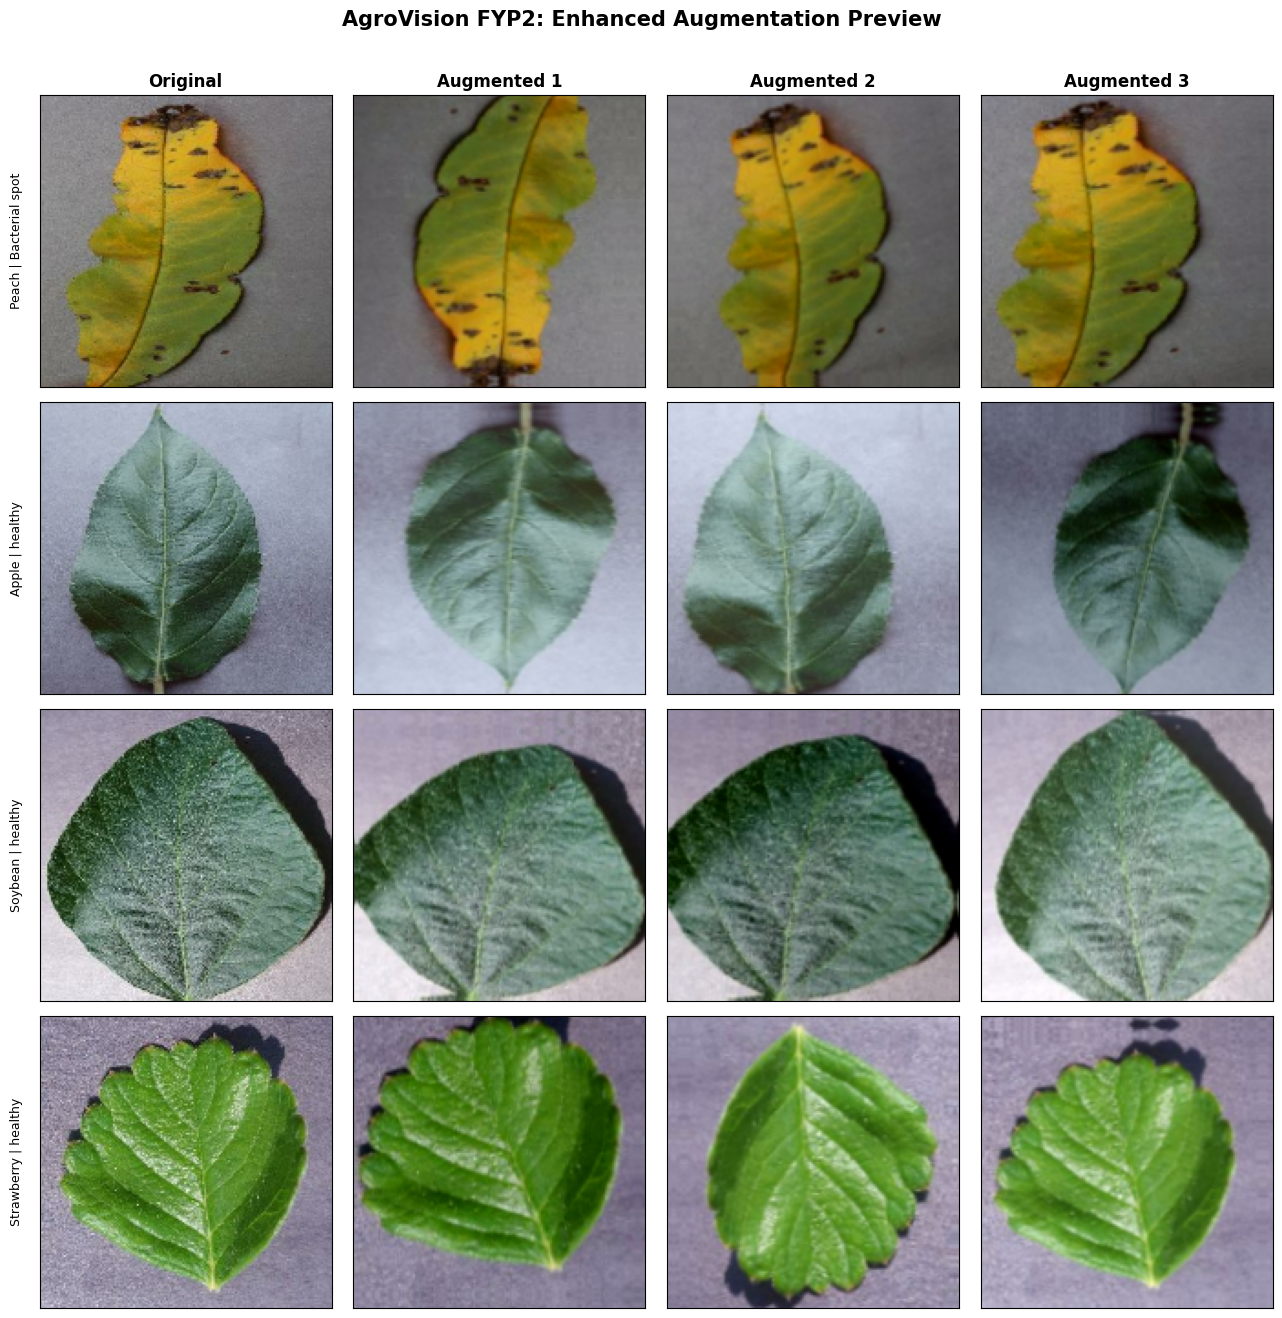


PASS: Augmentation visualisation completed.


In [7]:
# ============================================================
# SECTION 2.2: VISUALISE ENHANCED AUGMENTATION
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - AUGMENTATION VISUALISATION")
print("=" * 60)

# 1. Select four different classes
rng = np.random.default_rng(SEED)

selected_classes = rng.choice(
    sorted(class_to_index.keys()),
    size=4,
    replace=False
)

selected_samples = []

for class_name in selected_classes:

    sample = train_data[
        train_data["plantvillage_class"] == class_name
    ].sample(
        n=1,
        random_state=SEED
    ).iloc[0]

    selected_samples.append(sample)

# 2. Create an augmentation pipeline for preview
preview_augmentation = create_augmentation(seed=SEED)

# 3. Set up visualisation
fig, axes = plt.subplots(
    nrows=4,
    ncols=4,
    figsize=(13, 13)
)

column_titles = [
    "Original",
    "Augmented 1",
    "Augmented 2",
    "Augmented 3"
]

# 4. Load and display images
for row_idx, sample in enumerate(selected_samples):

    image, _ = load_and_preprocess_image(
        str(sample["resolved_filepath"]),
        int(sample["label"])
    )

    # Original image
    axes[row_idx, 0].imshow(
        tf.cast(image, tf.uint8).numpy()
    )

    # Three random augmented versions
    for col_idx in range(1, 4):

        augmented_image = preview_augmentation(
            tf.expand_dims(image, axis=0),
            training=True
        )[0]

        augmented_image = tf.clip_by_value(
            augmented_image,
            0,
            255
        )

        axes[row_idx, col_idx].imshow(
            tf.cast(augmented_image, tf.uint8).numpy()
        )

    # Display class name
    class_label = sample["plantvillage_class"].replace(
        "___", " | "
    ).replace("_", " ")

    axes[row_idx, 0].set_ylabel(
        class_label,
        fontsize=9,
        rotation=90,
        labelpad=12
    )

# 5. Format figure
for row_idx in range(4):
    for col_idx in range(4):

        axes[row_idx, col_idx].set_xticks([])
        axes[row_idx, col_idx].set_yticks([])

        if row_idx == 0:
            axes[row_idx, col_idx].set_title(
                column_titles[col_idx],
                fontsize=12,
                fontweight="bold"
            )

plt.suptitle(
    "AgroVision FYP2: Enhanced Augmentation Preview",
    fontsize=15,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

print("\nPASS: Augmentation visualisation completed.")
print("=" * 60)


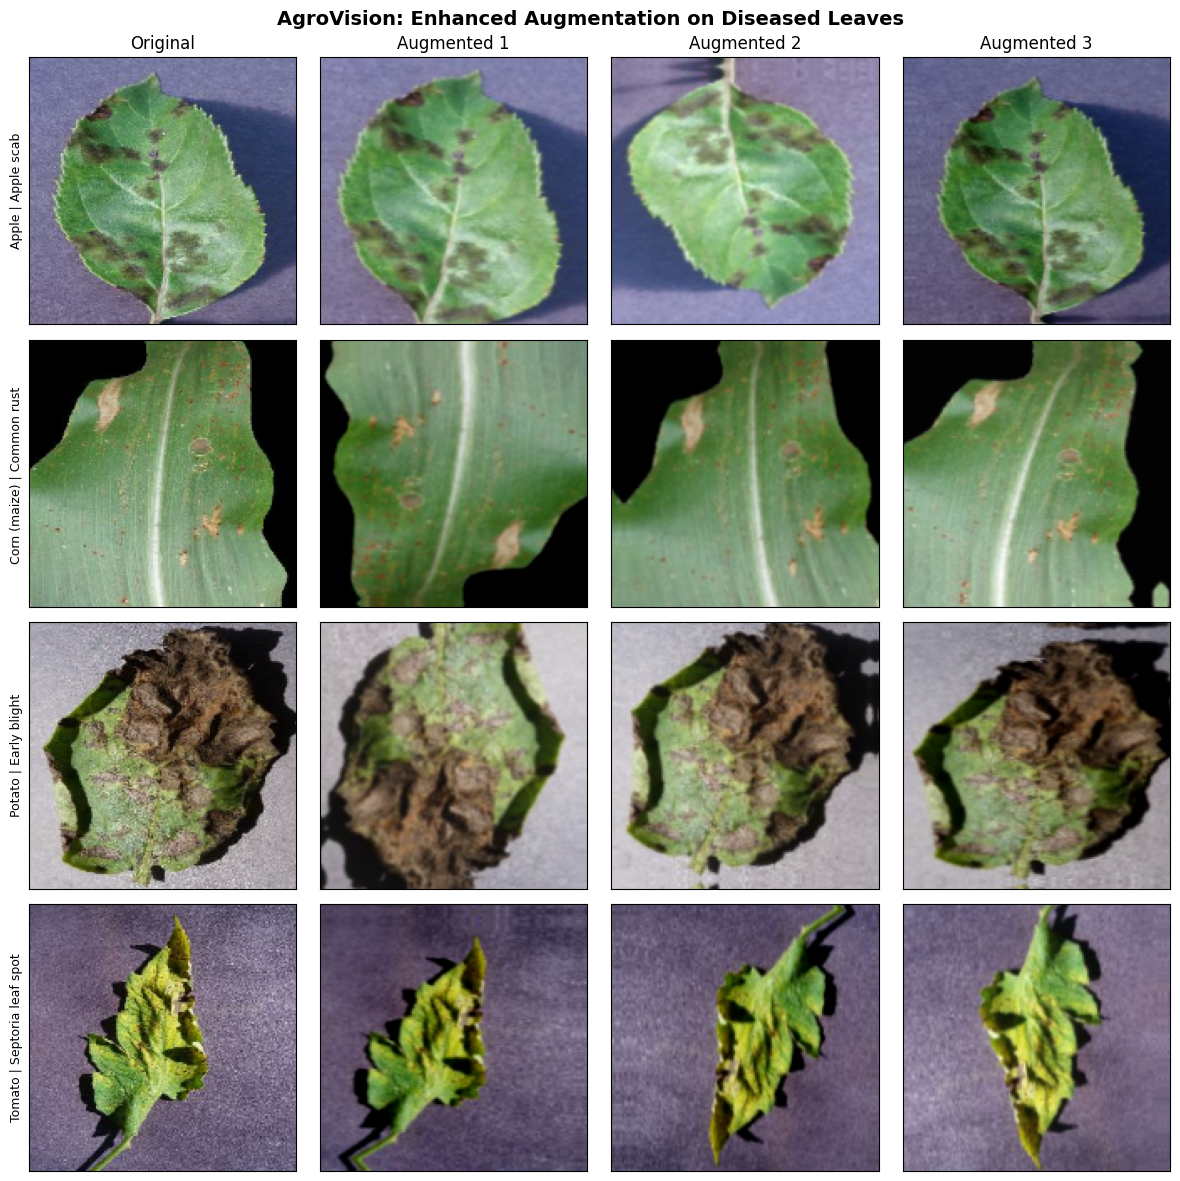

PASS: Diseased leaf augmentation preview completed.


In [8]:
# SECTION 2.3: AUGMENTATION CHECK ON DISEASED LEAVES

disease_keywords = [
    "Apple_scab",
    "Common_rust",
    "Early_blight",
    "Septoria_leaf_spot"
]

selected_classes = [
    next(name for name in class_to_index
         if keyword.lower() in name.lower())
    for keyword in disease_keywords
]

preview_aug = create_augmentation(seed=SEED + 10)
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
titles = ["Original", "Augmented 1", "Augmented 2", "Augmented 3"]

for row, class_name in enumerate(selected_classes):
    sample = train_data[
        train_data["plantvillage_class"] == class_name
    ].sample(n=1, random_state=SEED).iloc[0]

    image, _ = load_and_preprocess_image(
        str(sample["resolved_filepath"]),
        int(sample["label"])
    )

    axes[row, 0].imshow(
        tf.cast(image, tf.uint8).numpy()
    )

    for col in range(1, 4):
        augmented = preview_aug(
            tf.expand_dims(image, 0),
            training=True
        )[0]
        augmented = tf.clip_by_value(augmented, 0, 255)
        axes[row, col].imshow(
            tf.cast(augmented, tf.uint8).numpy()
        )

    axes[row, 0].set_ylabel(
        class_name.replace("___", " | ").replace("_", " "),
        fontsize=9
    )

for row in range(4):
    for col in range(4):
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
        if row == 0:
            axes[row, col].set_title(titles[col])

plt.suptitle(
    "AgroVision: Enhanced Augmentation on Diseased Leaves",
    fontsize=14,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

print("PASS: Diseased leaf augmentation preview completed.")


In [9]:
# SECTION 3.1: EFFICIENTNETB0 RETRAINING CONFIGURATION

print("=" * 60)
print("AGROVISION FYP2 - RETRAINING CONFIGURATION")
print("=" * 60)

# 1. Restore original training parameters
INITIAL_LEARNING_RATE = 1e-3
FINE_TUNING_LEARNING_RATE = 1e-5

INITIAL_EPOCHS = 50
FINE_TUNING_EPOCHS = 50

EARLY_STOPPING_PATIENCE = 7
EARLY_STOPPING_MIN_DELTA = 0.001

LR_REDUCTION_PATIENCE = 3
LR_REDUCTION_FACTOR = 0.5
MIN_LEARNING_RATE = 1e-7

DROPOUT_RATE = 0.3
MONITOR_METRIC = "val_loss"

# 2. Load original class weights
with open(required_files["Training class weights"], "r") as f:
    saved_class_weights = json.load(f)

class_weights = {
    int(index): float(weight)
    for index, weight in saved_class_weights.items()
}

assert set(class_weights.keys()) == set(range(NUM_CLASSES))
assert all(
    np.isfinite(weight) and weight > 0
    for weight in class_weights.values()
)

# 3. Verify class weights against training distribution
class_counts = train_data["label"].value_counts()

for class_index in range(NUM_CLASSES):
    expected_weight = (
        len(train_data) /
        (NUM_CLASSES * int(class_counts[class_index]))
    )
    assert np.isclose(
        class_weights[class_index],
        expected_weight,
        rtol=1e-5
    )

# 4. Prepare separate experiment directories
EXPERIMENT_DIR = PROJECT_DIR / "augmentation_retraining"
RUN_DIR = EXPERIMENT_DIR / "enhanced_v1"
EFFICIENTNET_DIR = RUN_DIR / "EfficientNetB0"

EFFICIENTNET_DIR.mkdir(parents=True, exist_ok=True)

# 5. Display configuration
print("\nTraining settings:")
print(f"Initial learning rate    : {INITIAL_LEARNING_RATE}")
print(f"Fine-tuning learning rate: {FINE_TUNING_LEARNING_RATE}")
print(f"Maximum initial epochs  : {INITIAL_EPOCHS}")
print(f"Maximum fine-tune epochs: {FINE_TUNING_EPOCHS}")
print(f"Early stopping patience : {EARLY_STOPPING_PATIENCE}")
print(f"Dropout rate            : {DROPOUT_RATE}")

print("\nClass weighting:")
print(f"Number of class weights : {len(class_weights)}")
print(f"Minimum weight          : {min(class_weights.values()):.4f}")
print(f"Maximum weight          : {max(class_weights.values()):.4f}")

print("\nExperiment directory:")
print(EFFICIENTNET_DIR)

print("\nPASS: Retraining configuration ready.")
print("=" * 60)


AGROVISION FYP2 - RETRAINING CONFIGURATION

Training settings:
Initial learning rate    : 0.001
Fine-tuning learning rate: 1e-05
Maximum initial epochs  : 50
Maximum fine-tune epochs: 50
Early stopping patience : 7
Dropout rate            : 0.3

Class weighting:
Number of class weights : 38
Minimum weight          : 0.2593
Maximum weight          : 9.4285

Experiment directory:
/content/drive/MyDrive/AgroVision_FYP2/augmentation_retraining/enhanced_v1/EfficientNetB0

PASS: Retraining configuration ready.


In [10]:
# SECTION 3.2: EFFICIENTNETB0 MODEL CONSTRUCTION

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 MODEL CONSTRUCTION")
print("=" * 60)

# 1. Set reproducibility
tf.keras.utils.set_random_seed(SEED)

# 2. Define model input
inputs = tf.keras.Input(
    shape=(*IMAGE_SIZE, IMAGE_CHANNELS),
    name="input_image"
)

# 3. Apply enhanced augmentation during training
x = create_augmentation(seed=SEED)(inputs)

# 4. EfficientNetB0 includes its own preprocessing
x = tf.keras.layers.Activation(
    "linear",
    name="efficientnet_input_passthrough"
)(x)

# 5. Load ImageNet-pretrained backbone
efficientnetb0_backbone = tf.keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMAGE_SIZE, IMAGE_CHANNELS)
)

# 6. Freeze backbone for Stage 1
efficientnetb0_backbone.trainable = False
x = efficientnetb0_backbone(x, training=False)

# 7. Build original classification head
x = tf.keras.layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = tf.keras.layers.Dropout(
    rate=DROPOUT_RATE,
    name="classifier_dropout"
)(x)

outputs = tf.keras.layers.Dense(
    units=NUM_CLASSES,
    activation="softmax",
    name="disease_predictions"
)(x)

# 8. Construct model
efficientnetb0_model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="AgroVision_EfficientNetB0"
)

# 9. Verify architecture
total_params = efficientnetb0_model.count_params()
trainable_params = sum(
    int(np.prod(w.shape))
    for w in efficientnetb0_model.trainable_weights
)

augmentation_layer = efficientnetb0_model.get_layer(
    "agrovision_enhanced_augmentation"
)

rescaling_layers = [
    layer for layer in efficientnetb0_backbone.layers
    if isinstance(layer, tf.keras.layers.Rescaling)
]

assert efficientnetb0_model.input_shape == (None, 160, 160, 3)
assert efficientnetb0_model.output_shape == (None, NUM_CLASSES)
assert not efficientnetb0_backbone.trainable
assert len(augmentation_layer.layers) == 6
assert len(rescaling_layers) > 0
assert trainable_params == (1280 + 1) * NUM_CLASSES

# 10. Display construction summary
print("\nModel architecture:")
print("Model name          :", efficientnetb0_model.name)
print("Backbone            :", efficientnetb0_backbone.name)
print("Input shape         :", efficientnetb0_model.input_shape)
print("Output shape        :", efficientnetb0_model.output_shape)
print("Pretrained weights  : ImageNet")
print("Backbone frozen     :", not efficientnetb0_backbone.trainable)
print("Augmentation layers :", len(augmentation_layer.layers))
print("Built-in rescaling  :", len(rescaling_layers))
print("Dropout rate        :", DROPOUT_RATE)

print("\nParameter summary:")
print(f"Total parameters    : {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters   : {total_params - trainable_params:,}")

print("\nPASS: EfficientNetB0 constructed successfully.")
print("=" * 60)


AGROVISION FYP2 - EFFICIENTNETB0 MODEL CONSTRUCTION
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

Model architecture:
Model name          : AgroVision_EfficientNetB0
Backbone            : efficientnetb0
Input shape         : (None, 160, 160, 3)
Output shape        : (None, 38)
Pretrained weights  : ImageNet
Backbone frozen     : True
Augmentation layers : 6
Built-in rescaling  : 2
Dropout rate        : 0.3

Parameter summary:
Total parameters    : 4,098,249
Trainable parameters: 48,678
Frozen parameters   : 4,049,571

PASS: EfficientNetB0 constructed successfully.


In [11]:
# SECTION 3.3: EFFICIENTNETB0 STAGE 1 COMPILATION

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 COMPILATION")
print("=" * 60)

# Verify frozen backbone
assert efficientnetb0_backbone.trainable is False
assert all(
    not layer.trainable
    for layer in efficientnetb0_backbone.layers
)

# Create a fresh Adam optimiser
efficientnetb0_stage1_optimizer = tf.keras.optimizers.Adam(
    learning_rate=INITIAL_LEARNING_RATE
)

# Compile model
efficientnetb0_model.compile(
    optimizer=efficientnetb0_stage1_optimizer,
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# Verify training configuration
actual_lr = float(
    efficientnetb0_model.optimizer.learning_rate.numpy()
)

trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in efficientnetb0_model.trainable_weights
)

assert np.isclose(actual_lr, INITIAL_LEARNING_RATE)
assert trainable_params == 48678
assert int(efficientnetb0_model.optimizer.iterations.numpy()) == 0
assert len(class_weights) == NUM_CLASSES

print("\nModel           :", efficientnetb0_model.name)
print("Training stage  : Stage 1 - Feature Extraction")
print("Optimiser       : Adam")
print("Learning rate   :", actual_lr)
print("Loss function   : SparseCategoricalCrossentropy")
print("Metric          : SparseCategoricalAccuracy")
print("Backbone frozen :", not efficientnetb0_backbone.trainable)
print("Trainable params:", f"{trainable_params:,}")

print("\nPASS: EfficientNetB0 Stage 1 compiled successfully.")
print("=" * 60)


AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 COMPILATION

Model           : AgroVision_EfficientNetB0
Training stage  : Stage 1 - Feature Extraction
Optimiser       : Adam
Learning rate   : 0.0010000000474974513
Loss function   : SparseCategoricalCrossentropy
Metric          : SparseCategoricalAccuracy
Backbone frozen : True
Trainable params: 48,678

PASS: EfficientNetB0 Stage 1 compiled successfully.


In [12]:
# SECTION 3.4: EFFICIENTNETB0 STAGE 1 CALLBACKS

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 CALLBACKS")
print("=" * 60)

# Create Stage 1 directory
EFFICIENTNET_STAGE1_DIR = EFFICIENTNET_DIR / "stage1"
EFFICIENTNET_STAGE1_DIR.mkdir(parents=True, exist_ok=True)

# Define output paths
efficientnetb0_stage1_checkpoint = (
    EFFICIENTNET_STAGE1_DIR / "best_model.keras"
)

efficientnetb0_stage1_history_path = (
    EFFICIENTNET_STAGE1_DIR / "training_history.csv"
)

efficientnetb0_stage1_log_path = (
    EFFICIENTNET_STAGE1_DIR / "epoch_log.csv"
)

efficientnetb0_stage1_curves_path = (
    EFFICIENTNET_STAGE1_DIR / "training_curves.png"
)

# Prevent accidental overwriting
output_files = [
    efficientnetb0_stage1_checkpoint,
    efficientnetb0_stage1_history_path,
    efficientnetb0_stage1_log_path,
    efficientnetb0_stage1_curves_path
]

existing_files = [path for path in output_files if path.exists()]

assert not existing_files, (
    "Existing experiment files detected:\n"
    + "\n".join(str(path) for path in existing_files)
)

# Configure callbacks
efficientnetb0_stage1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(efficientnetb0_stage1_checkpoint),
        monitor=MONITOR_METRIC,
        mode="min",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor=MONITOR_METRIC,
        mode="min",
        patience=EARLY_STOPPING_PATIENCE,
        min_delta=EARLY_STOPPING_MIN_DELTA,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor=MONITOR_METRIC,
        mode="min",
        factor=LR_REDUCTION_FACTOR,
        patience=LR_REDUCTION_PATIENCE,
        min_lr=MIN_LEARNING_RATE,
        verbose=1
    ),
    tf.keras.callbacks.CSVLogger(
        filename=str(efficientnetb0_stage1_log_path),
        append=False
    )
]

# Verify configuration
assert len(efficientnetb0_stage1_callbacks) == 4
assert EFFICIENTNET_STAGE1_DIR.is_dir()

print("\nOutput directory:")
print(EFFICIENTNET_STAGE1_DIR)

print("\nConfigured callbacks:")
for callback in efficientnetb0_stage1_callbacks:
    print("-", callback.__class__.__name__)

print("\nTraining settings:")
print("Maximum epochs        :", INITIAL_EPOCHS)
print("Monitoring metric     :", MONITOR_METRIC)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)
print("LR reduction patience :", LR_REDUCTION_PATIENCE)
print("LR reduction factor   :", LR_REDUCTION_FACTOR)

print("\nPASS: Stage 1 callbacks configured successfully.")
print("=" * 60)


AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 CALLBACKS

Output directory:
/content/drive/MyDrive/AgroVision_FYP2/augmentation_retraining/enhanced_v1/EfficientNetB0/stage1

Configured callbacks:
- ModelCheckpoint
- EarlyStopping
- ReduceLROnPlateau
- CSVLogger

Training settings:
Maximum epochs        : 50
Monitoring metric     : val_loss
Early stopping patience: 7
LR reduction patience : 3
LR reduction factor   : 0.5

PASS: Stage 1 callbacks configured successfully.


In [13]:
# SECTION 3.5: EFFICIENTNETB0 STAGE 1 READINESS CHECK

print("=" * 60)
print("AGROVISION FYP2 - STAGE 1 TRAINING READINESS")
print("=" * 60)

# 1. Verify GPU
gpus = tf.config.list_physical_devices("GPU")
assert len(gpus) > 0, "GPU not detected."

print("\nGPU verification:")
for gpu in gpus:
    print("Detected:", gpu)

# 2. Verify datasets
assert len(train_data) == 37978
assert len(val_data) == 8155
assert len(train_ds) == 1187
assert len(val_ds) == 255

print("\nDataset verification:")
print("Training images   :", len(train_data))
print("Validation images :", len(val_data))
print("Training batches  :", len(train_ds))
print("Validation batches:", len(val_ds))

# 3. Verify model and optimiser
assert efficientnetb0_backbone.trainable is False
assert efficientnetb0_model.optimizer is not None
assert int(efficientnetb0_model.optimizer.iterations.numpy()) == 0
assert np.isclose(
    float(efficientnetb0_model.optimizer.learning_rate.numpy()),
    INITIAL_LEARNING_RATE
)

# 4. Verify model predictions without training
sample_images, sample_labels = next(iter(val_ds))
predictions = efficientnetb0_model(
    sample_images,
    training=False
)

assert predictions.shape == (32, NUM_CLASSES)
tf.debugging.assert_all_finite(predictions, "Invalid predictions")
np.testing.assert_allclose(
    tf.reduce_sum(predictions, axis=1).numpy(),
    np.ones(32),
    atol=1e-5
)

print("\nModel verification:")
print("Model             :", efficientnetb0_model.name)
print("Backbone frozen   : Yes")
print("Prediction shape  :", predictions.shape)
print("Optimiser steps   :", efficientnetb0_model.optimizer.iterations.numpy())

# 5. Verify callbacks and class weights
assert len(efficientnetb0_stage1_callbacks) == 4
assert len(class_weights) == NUM_CLASSES

# 6. Prevent accidental overwriting
output_files = [
    efficientnetb0_stage1_checkpoint,
    efficientnetb0_stage1_history_path,
    efficientnetb0_stage1_log_path,
    efficientnetb0_stage1_curves_path
]

existing_files = [p for p in output_files if p.exists()]
assert not existing_files, (
    "Existing training outputs detected: "
    + ", ".join(str(p) for p in existing_files)
)

# 7. Verify Google Drive write access
write_test = EFFICIENTNET_STAGE1_DIR / "_write_test.tmp"

try:
    write_test.write_text("AgroVision storage test")
    assert write_test.is_file()
finally:
    write_test.unlink(missing_ok=True)

print("\nStorage verification:")
print("Output directory :", EFFICIENTNET_STAGE1_DIR)
print("Write access     : Confirmed")
print("Existing outputs : None")

print("\n" + "=" * 60)
print("PASS: EFFICIENTNETB0 STAGE 1 READY FOR TRAINING")
print("=" * 60)

print("\nNo training has been performed.")


AGROVISION FYP2 - STAGE 1 TRAINING READINESS

GPU verification:
Detected: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

Dataset verification:
Training images   : 37978
Validation images : 8155
Training batches  : 1187
Validation batches: 255

Model verification:
Model             : AgroVision_EfficientNetB0
Backbone frozen   : Yes
Prediction shape  : (32, 38)
Optimiser steps   : 0

Storage verification:
Output directory : /content/drive/MyDrive/AgroVision_FYP2/augmentation_retraining/enhanced_v1/EfficientNetB0/stage1
Write access     : Confirmed
Existing outputs : None

PASS: EFFICIENTNETB0 STAGE 1 READY FOR TRAINING

No training has been performed.


In [14]:
# SECTION 3.6: EFFICIENTNETB0 STAGE 1 TRAINING

import time

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 TRAINING")
print("=" * 60)

# 1. Prevent overwriting previous results
training_outputs = [
    efficientnetb0_stage1_checkpoint,
    efficientnetb0_stage1_history_path,
    efficientnetb0_stage1_log_path,
    efficientnetb0_stage1_curves_path
]

assert not any(path.exists() for path in training_outputs), (
    "Existing Stage 1 outputs detected. Review them before rerunning."
)

# 2. Verify training readiness
assert efficientnetb0_backbone.trainable is False
assert efficientnetb0_model.optimizer is not None
assert int(efficientnetb0_model.optimizer.iterations.numpy()) == 0
assert len(class_weights) == NUM_CLASSES
assert len(tf.config.list_physical_devices("GPU")) > 0

print("\nTraining configuration:")
print("Model             :", efficientnetb0_model.name)
print("Stage             : 1 - Feature Extraction")
print("Training images   :", len(train_data))
print("Validation images :", len(val_data))
print("Batch size        :", BATCH_SIZE)
print("Maximum epochs    :", INITIAL_EPOCHS)
print("Learning rate     :", INITIAL_LEARNING_RATE)
print("Class weighting   : Enabled")
print("Enhanced aug.     : Enabled")

# 3. Start training
print("\nStarting Stage 1 training...\n")

start_time = time.time()

efficientnetb0_stage1_history = efficientnetb0_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=INITIAL_EPOCHS,
    class_weight=class_weights,
    callbacks=efficientnetb0_stage1_callbacks,
    verbose=1
)

training_duration = time.time() - start_time

# 4. Save training history
efficientnetb0_stage1_history_df = pd.DataFrame(
    efficientnetb0_stage1_history.history
)

efficientnetb0_stage1_history_df.to_csv(
    efficientnetb0_stage1_history_path,
    index=False
)

# 5. Identify the best epoch
best_idx = int(
    efficientnetb0_stage1_history_df["val_loss"].idxmin()
)

efficientnetb0_stage1_best_epoch = best_idx + 1

best_val_loss = float(
    efficientnetb0_stage1_history_df.loc[best_idx, "val_loss"]
)

best_val_accuracy = float(
    efficientnetb0_stage1_history_df.loc[best_idx, "val_accuracy"]
)

# 6. Verify saved files
assert efficientnetb0_stage1_checkpoint.is_file()
assert efficientnetb0_stage1_history_path.is_file()
assert efficientnetb0_stage1_log_path.is_file()

# 7. Display training summary
print("\n" + "=" * 60)
print("EFFICIENTNETB0 STAGE 1 TRAINING COMPLETED")
print("=" * 60)

print(f"Epochs completed    : {len(efficientnetb0_stage1_history.epoch)}")
print(f"Training duration   : {training_duration / 60:.2f} minutes")
print(f"Best epoch          : {efficientnetb0_stage1_best_epoch}")
print(f"Best validation loss: {best_val_loss:.6f}")
print(f"Best validation acc.: {best_val_accuracy:.4%}")

print("\nSaved files:")
print("Checkpoint:", efficientnetb0_stage1_checkpoint)
print("History   :", efficientnetb0_stage1_history_path)
print("Epoch log :", efficientnetb0_stage1_log_path)

print("\nPASS: EfficientNetB0 Stage 1 training completed.")
print("=" * 60)


AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 TRAINING

Training configuration:
Model             : AgroVision_EfficientNetB0
Stage             : 1 - Feature Extraction
Training images   : 37978
Validation images : 8155
Batch size        : 32
Maximum epochs    : 50
Learning rate     : 0.001
Class weighting   : Enabled
Enhanced aug.     : Enabled

Starting Stage 1 training...

Epoch 1/50
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.6533 - loss: 1.5964
Epoch 1: val_loss improved from None to 0.48787, saving model to /content/drive/MyDrive/AgroVision_FYP2/augmentation_retraining/enhanced_v1/EfficientNetB0/stage1/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/AgroVision_FYP2/augmentation_retraining/enhanced_v1/EfficientNetB0/stage1/best_model.keras
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 95s 69ms/step - accuracy: 0.7803 - loss: 0.9798 - val_accuracy: 0.8586 - val_loss: 0.4879 - learning_rate: 0.0010
Epoch 2/50
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accurac

AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 CURVES


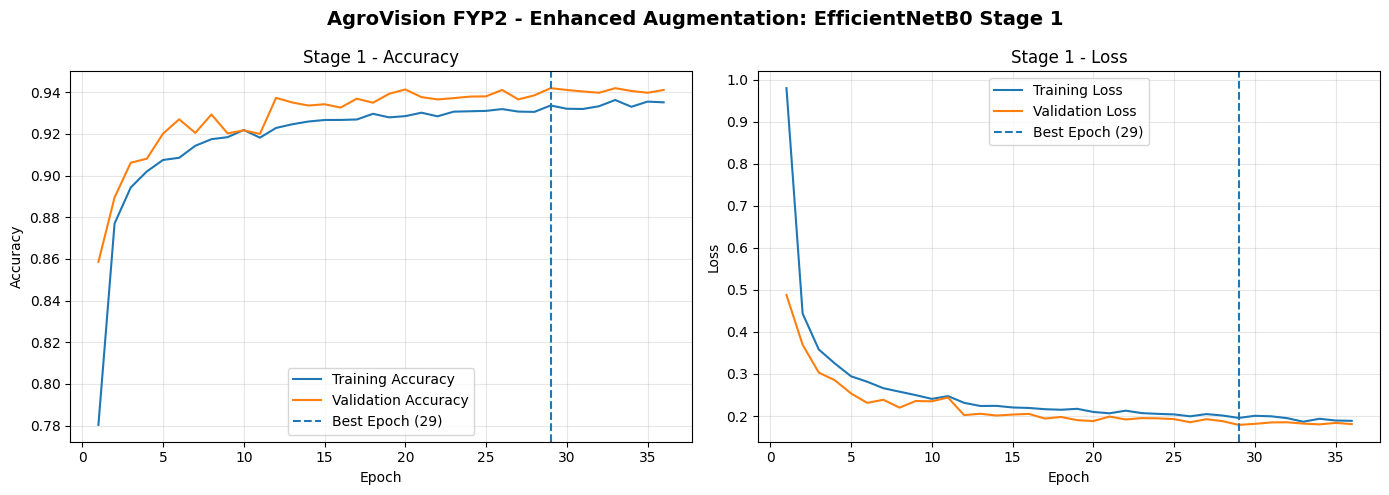


Training summary:
Epochs completed     : 36
Best epoch           : 29
Best validation loss : 0.178881
Best validation acc. : 94.1999%

Training curves saved: /content/drive/MyDrive/AgroVision_FYP2/augmentation_retraining/enhanced_v1/EfficientNetB0/stage1/training_curves.png

PASS: EfficientNetB0 Stage 1 curves saved.


In [15]:
# SECTION 3.7: EFFICIENTNETB0 STAGE 1 TRAINING CURVES

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 1 CURVES")
print("=" * 60)

# Load saved training history
history_df = pd.read_csv(efficientnetb0_stage1_history_path)

required_columns = {"accuracy", "val_accuracy", "loss", "val_loss"}
assert required_columns.issubset(history_df.columns)

epochs = np.arange(1, len(history_df) + 1)
best_idx = int(history_df["val_loss"].idxmin())
best_epoch = best_idx + 1

# Plot accuracy and loss
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history_df["accuracy"], label="Training Accuracy")
axes[0].plot(epochs, history_df["val_accuracy"], label="Validation Accuracy")
axes[0].axvline(best_epoch, linestyle="--", label=f"Best Epoch ({best_epoch})")
axes[0].set_title("Stage 1 - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history_df["loss"], label="Training Loss")
axes[1].plot(epochs, history_df["val_loss"], label="Validation Loss")
axes[1].axvline(best_epoch, linestyle="--", label=f"Best Epoch ({best_epoch})")
axes[1].set_title("Stage 1 - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle(
    "AgroVision FYP2 - Enhanced Augmentation: EfficientNetB0 Stage 1",
    fontsize=14,
    fontweight="bold"
)
plt.tight_layout()

# Save training curves
fig.savefig(
    efficientnetb0_stage1_curves_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Verify saved output
assert efficientnetb0_stage1_curves_path.is_file()
assert best_epoch == efficientnetb0_stage1_best_epoch

print("\nTraining summary:")
print(f"Epochs completed     : {len(history_df)}")
print(f"Best epoch           : {best_epoch}")
print(f"Best validation loss : {history_df.loc[best_idx, 'val_loss']:.6f}")
print(f"Best validation acc. : {history_df.loc[best_idx, 'val_accuracy']:.4%}")
print("\nTraining curves saved:", efficientnetb0_stage1_curves_path)
print("\nPASS: EfficientNetB0 Stage 1 curves saved.")
print("=" * 60)


In [16]:
# SECTION 3.8: EFFICIENTNETB0 STAGE 1 CHECKPOINT VERIFICATION

print("=" * 60)
print("AGROVISION FYP2 - STAGE 1 CHECKPOINT VERIFICATION")
print("=" * 60)

# 1. Verify saved files
assert efficientnetb0_stage1_checkpoint.is_file()
assert efficientnetb0_stage1_history_path.is_file()

# 2. Load the best Stage 1 model
efficientnetb0_stage1_best_model = tf.keras.models.load_model(
    str(efficientnetb0_stage1_checkpoint),
    compile=False,
    safe_mode=True
)

assert efficientnetb0_stage1_best_model.count_params() == 4098249
assert efficientnetb0_stage1_best_model.output_shape == (None, NUM_CLASSES)

# 3. Compile for validation
efficientnetb0_stage1_best_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# 4. Retrieve recorded best results
history_df = pd.read_csv(efficientnetb0_stage1_history_path)
best_idx = int(history_df["val_loss"].idxmin())
best_epoch = best_idx + 1

recorded_loss = float(history_df.loc[best_idx, "val_loss"])
recorded_accuracy = float(history_df.loc[best_idx, "val_accuracy"])

# 5. Evaluate the saved checkpoint
print("\nEvaluating saved checkpoint on validation images...")

evaluation = efficientnetb0_stage1_best_model.evaluate(
    val_ds,
    verbose=1,
    return_dict=True
)

evaluated_loss = float(evaluation["loss"])
evaluated_accuracy = float(evaluation["accuracy"])

# 6. Compare recorded and reproduced results
loss_difference = abs(recorded_loss - evaluated_loss)
accuracy_difference = abs(recorded_accuracy - evaluated_accuracy)

print("\nBest checkpoint epoch:", best_epoch)
print(f"Recorded validation loss    : {recorded_loss:.6f}")
print(f"Evaluated validation loss   : {evaluated_loss:.6f}")
print(f"Recorded validation accuracy: {recorded_accuracy:.4%}")
print(f"Evaluated validation accuracy: {evaluated_accuracy:.4%}")

print("\nAbsolute differences:")
print(f"Loss difference     : {loss_difference:.8f}")
print(f"Accuracy difference : {accuracy_difference:.8f}")

# 7. Final verification
assert best_epoch == 29
assert loss_difference < 1e-3
assert accuracy_difference < 1e-3

print("\nPASS: Best Stage 1 checkpoint verified.")
print("=" * 60)


AGROVISION FYP2 - STAGE 1 CHECKPOINT VERIFICATION

Evaluating saved checkpoint on validation images...
255/255 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - accuracy: 0.9420 - loss: 0.1789

Best checkpoint epoch: 29
Recorded validation loss    : 0.178881
Evaluated validation loss   : 0.178881
Recorded validation accuracy: 94.1999%
Evaluated validation accuracy: 94.1999%

Absolute differences:
Loss difference     : 0.00000000
Accuracy difference : 0.00000000

PASS: Best Stage 1 checkpoint verified.


In [17]:
# SECTION 4.1: EFFICIENTNETB0 STAGE 2 LAYER CONFIGURATION

import re

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 SETUP")
print("=" * 60)

# 1. Reload the best Stage 1 checkpoint
assert efficientnetb0_stage1_checkpoint.is_file()

efficientnetb0_stage2_model = tf.keras.models.load_model(
    str(efficientnetb0_stage1_checkpoint),
    compile=False,
    safe_mode=True
)

efficientnetb0_stage2_backbone = (
    efficientnetb0_stage2_model.get_layer("efficientnetb0")
)

assert efficientnetb0_stage2_model.count_params() == 4098249

# 2. Identify EfficientNetB0 regions
def identify_efficientnet_region(layer_name):
    match = re.match(r"^(block[1-7])[a-z]_", layer_name)

    if match:
        return match.group(1)

    if layer_name.startswith("top_"):
        return "top"

    return "stem_or_preprocessing"

# 3. Define fine-tuning regions
FINE_TUNING_REGIONS = {"block6", "block7", "top"}

CONV_LAYER_TYPES = (
    tf.keras.layers.Conv2D,
    tf.keras.layers.DepthwiseConv2D
)

# 4. Enable selective fine-tuning
efficientnetb0_stage2_backbone.trainable = True

for layer in efficientnetb0_stage2_backbone.layers:
    region = identify_efficientnet_region(layer.name)

    layer.trainable = (
        region in FINE_TUNING_REGIONS
        and isinstance(layer, CONV_LAYER_TYPES)
    )

# 5. Identify trainable and frozen layers
stage2_trainable_conv_layers = [
    layer for layer in efficientnetb0_stage2_backbone.layers
    if layer.trainable and isinstance(layer, CONV_LAYER_TYPES)
]

stage2_frozen_bn_layers = [
    layer for layer in efficientnetb0_stage2_backbone.layers
    if isinstance(layer, tf.keras.layers.BatchNormalization)
]

# 6. Calculate parameter counts
def count_weight_parameters(weights):
    return sum(int(np.prod(weight.shape)) for weight in weights)

stage2_backbone_trainable_params = count_weight_parameters(
    efficientnetb0_stage2_backbone.trainable_weights
)

stage2_total_trainable_params = count_weight_parameters(
    efficientnetb0_stage2_model.trainable_weights
)

stage2_total_params = efficientnetb0_stage2_model.count_params()

stage2_non_trainable_params = (
    stage2_total_params - stage2_total_trainable_params
)

# 7. Verify fine-tuning configuration
assert len(stage2_trainable_conv_layers) == 26
assert len(stage2_frozen_bn_layers) == 49
assert all(not layer.trainable for layer in stage2_frozen_bn_layers)
assert stage2_backbone_trainable_params == 3129884
assert stage2_total_trainable_params == 3178562
assert stage2_total_params == 4098249

# 8. Display summary
print("\nFine-tuning configuration:")
print("Selected regions       :", sorted(FINE_TUNING_REGIONS))
print("Trainable conv layers  :", len(stage2_trainable_conv_layers))
print("Frozen BatchNorm layers:", len(stage2_frozen_bn_layers))

print("\nParameter summary:")
print(f"Total parameters       : {stage2_total_params:,}")
print(f"Trainable parameters   : {stage2_total_trainable_params:,}")
print(f"Non-trainable params   : {stage2_non_trainable_params:,}")
print(f"Trainable backbone     : {stage2_backbone_trainable_params:,}")

print("\nTrainable convolutional layers:")
for layer in stage2_trainable_conv_layers:
    print(f"  {layer.name:<38}{layer.__class__.__name__}")

print("\nStage 1 checkpoint remains unchanged.")
print("No training has been performed.")

print("\nPASS: EfficientNetB0 Stage 2 layers configured.")
print("=" * 60)


AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 SETUP

Fine-tuning configuration:
Selected regions       : ['block6', 'block7', 'top']
Trainable conv layers  : 26
Frozen BatchNorm layers: 49

Parameter summary:
Total parameters       : 4,098,249
Trainable parameters   : 3,178,562
Non-trainable params   : 919,687
Trainable backbone     : 3,129,884

Trainable convolutional layers:
  block6a_expand_conv                   Conv2D
  block6a_dwconv                        DepthwiseConv2D
  block6a_se_reduce                     Conv2D
  block6a_se_expand                     Conv2D
  block6a_project_conv                  Conv2D
  block6b_expand_conv                   Conv2D
  block6b_dwconv                        DepthwiseConv2D
  block6b_se_reduce                     Conv2D
  block6b_se_expand                     Conv2D
  block6b_project_conv                  Conv2D
  block6c_expand_conv                   Conv2D
  block6c_dwconv                        DepthwiseConv2D
  block6c_se_reduce               

In [18]:
# SECTION 4.2: EFFICIENTNETB0 STAGE 2 COMPILATION

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 COMPILATION")
print("=" * 60)

# Verify fine-tuning configuration
assert efficientnetb0_stage2_backbone.trainable
assert len(stage2_trainable_conv_layers) == 26
assert all(not layer.trainable for layer in stage2_frozen_bn_layers)
assert stage2_total_trainable_params == 3178562

# Create a fresh optimiser for fine-tuning
efficientnetb0_stage2_optimizer = tf.keras.optimizers.Adam(
    learning_rate=FINE_TUNING_LEARNING_RATE
)

# Compile Stage 2 model
efficientnetb0_stage2_model.compile(
    optimizer=efficientnetb0_stage2_optimizer,
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# Verify optimiser and model parameters
actual_lr = float(
    efficientnetb0_stage2_model.optimizer.learning_rate.numpy()
)

optimizer_steps = int(
    efficientnetb0_stage2_model.optimizer.iterations.numpy()
)

trainable_params = count_weight_parameters(
    efficientnetb0_stage2_model.trainable_weights
)

assert np.isclose(actual_lr, FINE_TUNING_LEARNING_RATE)
assert optimizer_steps == 0
assert trainable_params == 3178562
assert len(class_weights) == NUM_CLASSES

print("\nModel configuration:")
print("Model             :", efficientnetb0_stage2_model.name)
print("Training stage    : Stage 2 - Selective Fine-Tuning")
print("Fine-tuning       : block6, block7, top")
print("BatchNorm frozen  : Yes")

print("\nOptimisation:")
print("Optimiser         : Adam")
print(f"Learning rate     : {actual_lr:.8f}")
print("Loss function     : SparseCategoricalCrossentropy")
print("Metric            : SparseCategoricalAccuracy")
print("Optimiser steps   :", optimizer_steps)

print("\nModel parameters:")
print(f"Trainable         : {trainable_params:,}")
print(f"Non-trainable     : {stage2_non_trainable_params:,}")

print("\nPASS: EfficientNetB0 Stage 2 compiled successfully.")
print("=" * 60)


AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 COMPILATION

Model configuration:
Model             : AgroVision_EfficientNetB0
Training stage    : Stage 2 - Selective Fine-Tuning
Fine-tuning       : block6, block7, top
BatchNorm frozen  : Yes

Optimisation:
Optimiser         : Adam
Learning rate     : 0.00001000
Loss function     : SparseCategoricalCrossentropy
Metric            : SparseCategoricalAccuracy
Optimiser steps   : 0

Model parameters:
Trainable         : 3,178,562
Non-trainable     : 919,687

PASS: EfficientNetB0 Stage 2 compiled successfully.


In [19]:
# SECTION 4.3: EFFICIENTNETB0 STAGE 2 CALLBACKS

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 CALLBACKS")
print("=" * 60)

# Create Stage 2 directory
EFFICIENTNET_STAGE2_DIR = EFFICIENTNET_DIR / "stage2"
EFFICIENTNET_STAGE2_DIR.mkdir(parents=True, exist_ok=True)

# Define Stage 2 output paths
efficientnetb0_stage2_checkpoint = (
    EFFICIENTNET_STAGE2_DIR / "best_model.keras"
)

efficientnetb0_stage2_history_path = (
    EFFICIENTNET_STAGE2_DIR / "training_history.csv"
)

efficientnetb0_stage2_log_path = (
    EFFICIENTNET_STAGE2_DIR / "epoch_log.csv"
)

efficientnetb0_stage2_curves_path = (
    EFFICIENTNET_STAGE2_DIR / "training_curves.png"
)

# Prevent accidental overwriting
stage2_output_files = [
    efficientnetb0_stage2_checkpoint,
    efficientnetb0_stage2_history_path,
    efficientnetb0_stage2_log_path,
    efficientnetb0_stage2_curves_path
]

existing_files = [
    path for path in stage2_output_files if path.exists()
]

assert not existing_files, (
    "Existing Stage 2 outputs detected:\n"
    + "\n".join(str(path) for path in existing_files)
)

# Configure callbacks
efficientnetb0_stage2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(efficientnetb0_stage2_checkpoint),
        monitor=MONITOR_METRIC,
        mode="min",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor=MONITOR_METRIC,
        mode="min",
        patience=EARLY_STOPPING_PATIENCE,
        min_delta=EARLY_STOPPING_MIN_DELTA,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor=MONITOR_METRIC,
        mode="min",
        factor=LR_REDUCTION_FACTOR,
        patience=LR_REDUCTION_PATIENCE,
        min_lr=MIN_LEARNING_RATE,
        verbose=1
    ),
    tf.keras.callbacks.CSVLogger(
        filename=str(efficientnetb0_stage2_log_path),
        append=False
    )
]

# Verify configuration
assert len(efficientnetb0_stage2_callbacks) == 4
assert efficientnetb0_stage1_checkpoint.is_file()
assert efficientnetb0_stage2_checkpoint != efficientnetb0_stage1_checkpoint
assert EFFICIENTNET_STAGE2_DIR.is_dir()

print("\nStage 2 directory:")
print(EFFICIENTNET_STAGE2_DIR)

print("\nConfigured callbacks:")
for callback in efficientnetb0_stage2_callbacks:
    print("-", callback.__class__.__name__)

print("\nTraining configuration:")
print("Maximum epochs         :", FINE_TUNING_EPOCHS)
print("Initial learning rate  :", FINE_TUNING_LEARNING_RATE)
print("Monitor metric         :", MONITOR_METRIC)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)
print("LR reduction patience  :", LR_REDUCTION_PATIENCE)
print("LR reduction factor    :", LR_REDUCTION_FACTOR)

print("\nStage 1 checkpoint remains preserved.")
print("\nPASS: EfficientNetB0 Stage 2 callbacks configured.")
print("=" * 60)


AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 CALLBACKS

Stage 2 directory:
/content/drive/MyDrive/AgroVision_FYP2/augmentation_retraining/enhanced_v1/EfficientNetB0/stage2

Configured callbacks:
- ModelCheckpoint
- EarlyStopping
- ReduceLROnPlateau
- CSVLogger

Training configuration:
Maximum epochs         : 50
Initial learning rate  : 1e-05
Monitor metric         : val_loss
Early stopping patience: 7
LR reduction patience  : 3
LR reduction factor    : 0.5

Stage 1 checkpoint remains preserved.

PASS: EfficientNetB0 Stage 2 callbacks configured.


In [20]:
# SECTION 4.4: EFFICIENTNETB0 STAGE 2 READINESS CHECK

print("=" * 60)
print("AGROVISION FYP2 - STAGE 2 TRAINING READINESS")
print("=" * 60)

# 1. Verify GPU availability
assert tf.config.list_physical_devices("GPU"), "GPU not detected."

# 2. Verify dataset sizes
assert len(train_data) == 37978
assert len(val_data) == 8155
assert len(train_ds) == 1187
assert len(val_ds) == 255

# 3. Verify fine-tuning configuration
assert efficientnetb0_stage2_backbone.trainable
assert len(stage2_trainable_conv_layers) == 26
assert all(not layer.trainable for layer in stage2_frozen_bn_layers)
assert count_weight_parameters(
    efficientnetb0_stage2_model.trainable_weights
) == 3178562

# 4. Verify optimiser
assert efficientnetb0_stage2_model.optimizer is not None
assert np.isclose(
    float(efficientnetb0_stage2_model.optimizer.learning_rate.numpy()),
    FINE_TUNING_LEARNING_RATE
)
assert int(efficientnetb0_stage2_model.optimizer.iterations.numpy()) == 0

# 5. Verify model predictions
sample_images, _ = next(iter(val_ds))
predictions = efficientnetb0_stage2_model(
    sample_images[:2],
    training=False
)

assert predictions.shape == (2, NUM_CLASSES)
tf.debugging.assert_all_finite(predictions, "Invalid predictions")

# 6. Verify saved checkpoint and output directory
assert efficientnetb0_stage1_checkpoint.is_file()
assert EFFICIENTNET_STAGE2_DIR.is_dir()
assert len(efficientnetb0_stage2_callbacks) == 4
assert len(class_weights) == NUM_CLASSES

existing_files = [
    path for path in stage2_output_files if path.exists()
]

assert not existing_files, (
    "Existing Stage 2 outputs detected:\n"
    + "\n".join(str(path) for path in existing_files)
)

# 7. Display verification results
print("\nGPU detected           : Yes")
print("Training images        :", len(train_data))
print("Validation images      :", len(val_data))
print("Trainable conv layers  :", len(stage2_trainable_conv_layers))
print("BatchNorm layers frozen: Yes")
print("Learning rate          :", FINE_TUNING_LEARNING_RATE)
print("Optimiser steps        : 0")
print("Prediction shape       :", predictions.shape)
print("Stage 1 checkpoint     : Available")
print("Stage 2 output files   : No conflicts")

print("\n" + "=" * 60)
print("PASS: EFFICIENTNETB0 STAGE 2 READY FOR TRAINING")
print("=" * 60)


AGROVISION FYP2 - STAGE 2 TRAINING READINESS

GPU detected           : Yes
Training images        : 37978
Validation images      : 8155
Trainable conv layers  : 26
BatchNorm layers frozen: Yes
Learning rate          : 1e-05
Optimiser steps        : 0
Prediction shape       : (2, 38)
Stage 1 checkpoint     : Available
Stage 2 output files   : No conflicts

PASS: EFFICIENTNETB0 STAGE 2 READY FOR TRAINING


In [21]:
# SECTION 4.5: EFFICIENTNETB0 STAGE 2 FINE-TUNING

import time

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 FINE-TUNING")
print("=" * 60)

# 1. Prevent accidental overwriting
assert not any(path.exists() for path in stage2_output_files), (
    "Existing Stage 2 outputs detected. Do not overwrite."
)

# 2. Verify training configuration
assert efficientnetb0_stage2_backbone.trainable
assert len(stage2_trainable_conv_layers) == 26
assert all(not layer.trainable for layer in stage2_frozen_bn_layers)
assert int(efficientnetb0_stage2_model.optimizer.iterations.numpy()) == 0
assert len(class_weights) == NUM_CLASSES
assert len(tf.config.list_physical_devices("GPU")) > 0

print("\nTraining configuration:")
print("Model             :", efficientnetb0_stage2_model.name)
print("Stage             : 2 - Selective Fine-Tuning")
print("Training images   :", len(train_data))
print("Validation images :", len(val_data))
print("Batch size        :", BATCH_SIZE)
print("Maximum epochs    :", FINE_TUNING_EPOCHS)
print("Learning rate     :", FINE_TUNING_LEARNING_RATE)
print("Trainable layers  :", len(stage2_trainable_conv_layers))
print("Class weighting   : Enabled")
print("Enhanced aug.     : Enabled")

# 3. Start fine-tuning
print("\nStarting Stage 2 fine-tuning...\n")

start_time = time.time()

efficientnetb0_stage2_history = efficientnetb0_stage2_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNING_EPOCHS,
    class_weight=class_weights,
    callbacks=efficientnetb0_stage2_callbacks,
    verbose=1
)

training_duration = time.time() - start_time

# 4. Save training history
efficientnetb0_stage2_history_df = pd.DataFrame(
    efficientnetb0_stage2_history.history
)

efficientnetb0_stage2_history_df.to_csv(
    efficientnetb0_stage2_history_path,
    index=False
)

# 5. Identify best epoch
best_idx = int(
    efficientnetb0_stage2_history_df["val_loss"].idxmin()
)

efficientnetb0_stage2_best_epoch = best_idx + 1

best_val_loss = float(
    efficientnetb0_stage2_history_df.loc[best_idx, "val_loss"]
)

best_val_accuracy = float(
    efficientnetb0_stage2_history_df.loc[best_idx, "val_accuracy"]
)

# 6. Verify saved outputs
assert efficientnetb0_stage2_checkpoint.is_file()
assert efficientnetb0_stage2_history_path.is_file()
assert efficientnetb0_stage2_log_path.is_file()

# 7. Display training summary
print("\n" + "=" * 60)
print("EFFICIENTNETB0 STAGE 2 FINE-TUNING COMPLETED")
print("=" * 60)

print(f"Epochs completed    : {len(efficientnetb0_stage2_history.epoch)}")
print(f"Training duration   : {training_duration / 60:.2f} minutes")
print(f"Best epoch          : {efficientnetb0_stage2_best_epoch}")
print(f"Best validation loss: {best_val_loss:.6f}")
print(f"Best validation acc.: {best_val_accuracy:.4%}")

print("\nSaved files:")
print("Checkpoint:", efficientnetb0_stage2_checkpoint)
print("History   :", efficientnetb0_stage2_history_path)
print("Epoch log :", efficientnetb0_stage2_log_path)

print("\nPASS: EfficientNetB0 Stage 2 fine-tuning completed.")
print("=" * 60)


AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 FINE-TUNING

Training configuration:
Model             : AgroVision_EfficientNetB0
Stage             : 2 - Selective Fine-Tuning
Training images   : 37978
Validation images : 8155
Batch size        : 32
Maximum epochs    : 50
Learning rate     : 1e-05
Trainable layers  : 26
Class weighting   : Enabled
Enhanced aug.     : Enabled

Starting Stage 2 fine-tuning...

Epoch 1/50
1186/1187 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9407 - loss: 0.1741
Epoch 1: val_loss improved from None to 0.13515, saving model to /content/drive/MyDrive/AgroVision_FYP2/augmentation_retraining/enhanced_v1/EfficientNetB0/stage2/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/AgroVision_FYP2/augmentation_retraining/enhanced_v1/EfficientNetB0/stage2/best_model.keras
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 105s 77ms/step - accuracy: 0.9439 - loss: 0.1625 - val_accuracy: 0.9543 - val_loss: 0.1352 - learning_rate: 1.0000e-05
Epoch 2/50
1187/1187 ━━━━━━

AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 CURVES


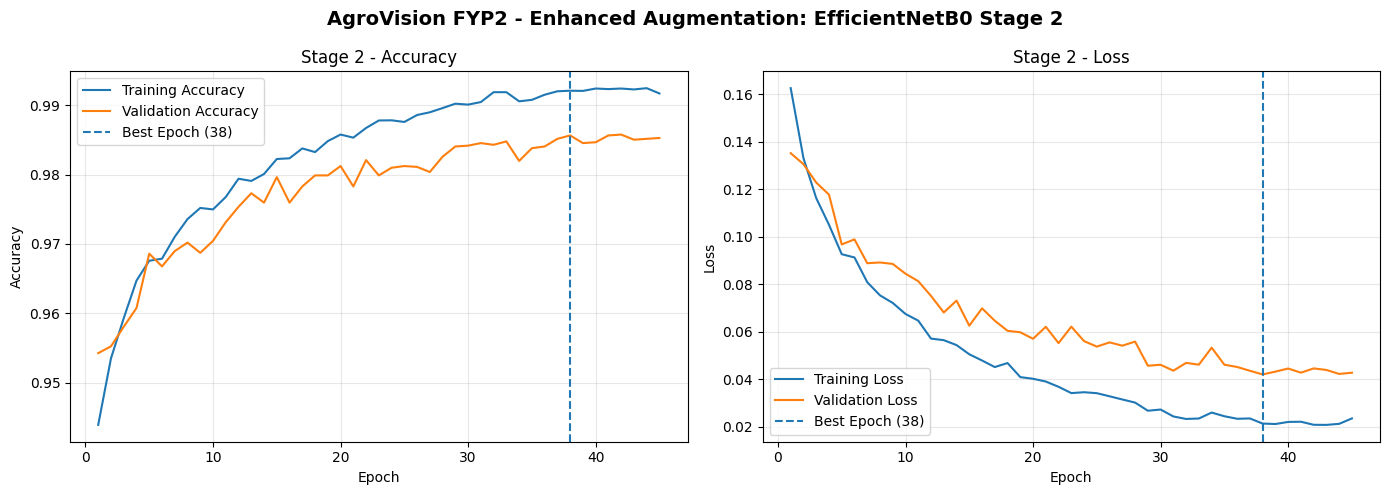


Training summary:
Epochs completed     : 45
Best epoch           : 38
Best validation loss : 0.041946
Best validation acc. : 98.5653%

Training curves saved: /content/drive/MyDrive/AgroVision_FYP2/augmentation_retraining/enhanced_v1/EfficientNetB0/stage2/training_curves.png

PASS: EfficientNetB0 Stage 2 curves saved.


In [22]:
# SECTION 4.6: EFFICIENTNETB0 STAGE 2 TRAINING CURVES

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 STAGE 2 CURVES")
print("=" * 60)

# Load saved Stage 2 history
history_df = pd.read_csv(efficientnetb0_stage2_history_path)

required_columns = {"accuracy", "val_accuracy", "loss", "val_loss"}
assert required_columns.issubset(history_df.columns)

epochs = np.arange(1, len(history_df) + 1)
best_idx = int(history_df["val_loss"].idxmin())
best_epoch = best_idx + 1

# Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history_df["accuracy"], label="Training Accuracy")
axes[0].plot(epochs, history_df["val_accuracy"], label="Validation Accuracy")
axes[0].axvline(best_epoch, linestyle="--", label=f"Best Epoch ({best_epoch})")
axes[0].set_title("Stage 2 - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history_df["loss"], label="Training Loss")
axes[1].plot(epochs, history_df["val_loss"], label="Validation Loss")
axes[1].axvline(best_epoch, linestyle="--", label=f"Best Epoch ({best_epoch})")
axes[1].set_title("Stage 2 - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle(
    "AgroVision FYP2 - Enhanced Augmentation: EfficientNetB0 Stage 2",
    fontsize=14,
    fontweight="bold"
)
plt.tight_layout()

# Save figure
fig.savefig(
    efficientnetb0_stage2_curves_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Verify results
assert efficientnetb0_stage2_curves_path.is_file()
assert best_epoch == 38

print("\nTraining summary:")
print(f"Epochs completed     : {len(history_df)}")
print(f"Best epoch           : {best_epoch}")
print(f"Best validation loss : {history_df.loc[best_idx, 'val_loss']:.6f}")
print(f"Best validation acc. : {history_df.loc[best_idx, 'val_accuracy']:.4%}")

print("\nTraining curves saved:", efficientnetb0_stage2_curves_path)
print("\nPASS: EfficientNetB0 Stage 2 curves saved.")
print("=" * 60)


In [23]:
# SECTION 4.7: EFFICIENTNETB0 STAGE 2 CHECKPOINT VERIFICATION

print("=" * 60)
print("AGROVISION FYP2 - STAGE 2 CHECKPOINT VERIFICATION")
print("=" * 60)

# 1. Verify saved checkpoint and training history
assert efficientnetb0_stage2_checkpoint.is_file()
assert efficientnetb0_stage2_history_path.is_file()

# 2. Load the best Stage 2 checkpoint
efficientnetb0_final_model = tf.keras.models.load_model(
    str(efficientnetb0_stage2_checkpoint),
    compile=False,
    safe_mode=True
)

assert efficientnetb0_final_model.count_params() == 4098249
assert efficientnetb0_final_model.output_shape == (None, NUM_CLASSES)

# 3. Compile the loaded model for evaluation
efficientnetb0_final_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINE_TUNING_LEARNING_RATE
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# 4. Retrieve recorded best validation results
stage2_history_df = pd.read_csv(
    efficientnetb0_stage2_history_path
)

best_idx = int(stage2_history_df["val_loss"].idxmin())
best_epoch = best_idx + 1

recorded_loss = float(
    stage2_history_df.loc[best_idx, "val_loss"]
)
recorded_accuracy = float(
    stage2_history_df.loc[best_idx, "val_accuracy"]
)

# 5. Evaluate the saved model
print("\nEvaluating final checkpoint on validation set...")

evaluation = efficientnetb0_final_model.evaluate(
    val_ds,
    verbose=1,
    return_dict=True
)

evaluated_loss = float(evaluation["loss"])
evaluated_accuracy = float(evaluation["accuracy"])

# 6. Compare results
loss_difference = abs(recorded_loss - evaluated_loss)
accuracy_difference = abs(recorded_accuracy - evaluated_accuracy)

print("\nBest checkpoint epoch:", best_epoch)
print(f"Recorded validation loss    : {recorded_loss:.6f}")
print(f"Evaluated validation loss   : {evaluated_loss:.6f}")
print(f"Recorded validation accuracy: {recorded_accuracy:.4%}")
print(f"Evaluated validation accuracy: {evaluated_accuracy:.4%}")

print("\nAbsolute differences:")
print(f"Loss difference     : {loss_difference:.8f}")
print(f"Accuracy difference : {accuracy_difference:.8f}")

# 7. Verify checkpoint consistency
assert best_epoch == 38
assert loss_difference < 1e-3
assert accuracy_difference < 1e-3

print("\nPASS: Final EfficientNetB0 checkpoint verified.")
print("=" * 60)


AGROVISION FYP2 - STAGE 2 CHECKPOINT VERIFICATION

Evaluating final checkpoint on validation set...
255/255 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.9857 - loss: 0.0419

Best checkpoint epoch: 38
Recorded validation loss    : 0.041946
Evaluated validation loss   : 0.041946
Recorded validation accuracy: 98.5653%
Evaluated validation accuracy: 98.5653%

Absolute differences:
Loss difference     : 0.00000000
Accuracy difference : 0.00000000

PASS: Final EfficientNetB0 checkpoint verified.


In [24]:
# SECTION 5.1: EFFICIENTNETB0 PLANTVILLAGE TEST EVALUATION

import json

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 PLANTVILLAGE TEST")
print("=" * 60)

# 1. Prepare evaluation directory
EFFICIENTNET_EVAL_DIR = EFFICIENTNET_DIR / "evaluation"
EFFICIENTNET_PV_DIR = EFFICIENTNET_EVAL_DIR / "plantvillage"
EFFICIENTNET_PV_DIR.mkdir(parents=True, exist_ok=True)

efficientnetb0_pv_summary_path = (
    EFFICIENTNET_PV_DIR / "test_summary.json"
)

# 2. Verify controlled test configuration
assert efficientnetb0_stage2_checkpoint.is_file()
assert len(test_data) == 8151
assert test_data["label"].nunique() == NUM_CLASSES
assert len(test_ds) == 255
assert efficientnetb0_final_model.output_shape == (None, NUM_CLASSES)

print("\nEvaluation configuration:")
print("Model          : EfficientNetB0")
print("Checkpoint     : Stage 2, best epoch 38")
print("Dataset        : PlantVillage controlled test")
print("Test images    :", len(test_data))
print("Classes        :", NUM_CLASSES)
print("Augmentation   : Disabled during evaluation")

# 3. Evaluate the final model
print("\nEvaluating reserved PlantVillage test images...\n")

pv_evaluation = efficientnetb0_final_model.evaluate(
    test_ds,
    verbose=1,
    return_dict=True
)

pv_test_loss = float(pv_evaluation["loss"])
pv_test_accuracy = float(pv_evaluation["accuracy"])

# 4. Prepare evaluation summary
pv_summary = {
    "model": "EfficientNetB0",
    "experiment": "enhanced_v1",
    "checkpoint": str(efficientnetb0_stage2_checkpoint),
    "dataset": "PlantVillage",
    "test_images": len(test_data),
    "num_classes": NUM_CLASSES,
    "test_loss": pv_test_loss,
    "test_accuracy": pv_test_accuracy
}

# 5. Save results without overwriting different outputs
if efficientnetb0_pv_summary_path.exists():
    with open(efficientnetb0_pv_summary_path, "r") as f:
        saved_summary = json.load(f)

    assert saved_summary["checkpoint"] == pv_summary["checkpoint"]
    assert np.isclose(saved_summary["test_loss"], pv_test_loss, atol=1e-4)
    assert np.isclose(saved_summary["test_accuracy"], pv_test_accuracy, atol=1e-4)
    print("\nExisting evaluation summary verified.")
else:
    with open(efficientnetb0_pv_summary_path, "w") as f:
        json.dump(pv_summary, f, indent=4)
    print("\nEvaluation summary saved.")

# 6. Display final results
print("\n" + "=" * 60)
print("EFFICIENTNETB0 - PLANTVILLAGE TEST RESULTS")
print("=" * 60)

print(f"Test images    : {len(test_data):,}")
print(f"Test accuracy  : {pv_test_accuracy:.4%}")
print(f"Test loss      : {pv_test_loss:.6f}")
print(f"Original acc.  : 98.52%")
print(f"Accuracy change: {(pv_test_accuracy * 100) - 98.52:+.2f} percentage points")

print("\nSaved to:", efficientnetb0_pv_summary_path)
print("\nPASS: PlantVillage controlled test completed.")
print("=" * 60)


AGROVISION FYP2 - EFFICIENTNETB0 PLANTVILLAGE TEST

Evaluation configuration:
Model          : EfficientNetB0
Checkpoint     : Stage 2, best epoch 38
Dataset        : PlantVillage controlled test
Test images    : 8151
Classes        : 38
Augmentation   : Disabled during evaluation

Evaluating reserved PlantVillage test images...

255/255 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - accuracy: 0.9843 - loss: 0.0502

Evaluation summary saved.

EFFICIENTNETB0 - PLANTVILLAGE TEST RESULTS
Test images    : 8,151
Test accuracy  : 98.4296%
Test loss      : 0.050204
Original acc.  : 98.52%
Accuracy change: -0.09 percentage points

Saved to: /content/drive/MyDrive/AgroVision_FYP2/augmentation_retraining/enhanced_v1/EfficientNetB0/evaluation/plantvillage/test_summary.json

PASS: PlantVillage controlled test completed.


In [25]:
# SECTION 5.2: EFFICIENTNETB0 PLANTVILLAGE CLASSIFICATION METRICS

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support
)

print("=" * 60)
print("AGROVISION FYP2 - PLANTVILLAGE CLASSIFICATION METRICS")
print("=" * 60)

# 1. Define output files and class order
pv_predictions_path = EFFICIENTNET_PV_DIR / "predictions.csv"
pv_metrics_path = EFFICIENTNET_PV_DIR / "per_class_metrics.csv"

assert not pv_predictions_path.exists()
assert not pv_metrics_path.exists()

class_names = [
    name for name, index in sorted(
        class_to_index.items(), key=lambda item: item[1]
    )
]
assert len(class_names) == NUM_CLASSES

# 2. Generate predictions and collect corresponding labels
all_true, all_pred = [], []

for batch_images, batch_labels in test_ds:
    probabilities = efficientnetb0_final_model(
        batch_images, training=False
    )
    all_true.extend(batch_labels.numpy())
    all_pred.extend(
        tf.argmax(probabilities, axis=1).numpy()
    )

y_true = np.asarray(all_true, dtype=int)
y_pred = np.asarray(all_pred, dtype=int)

assert len(y_true) == len(y_pred) == 8151
assert np.all((y_pred >= 0) & (y_pred < NUM_CLASSES))

# 3. Verify consistency with Cell 25
calculated_accuracy = accuracy_score(y_true, y_pred)
assert np.isclose(calculated_accuracy, pv_test_accuracy, atol=1e-5)

# 4. Calculate per-class metrics
precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    zero_division=0
)

pv_metrics_df = pd.DataFrame({
    "class_index": np.arange(NUM_CLASSES),
    "class_name": class_names,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "support": support
})

# 5. Save predictions and class metrics
pv_predictions_df = pd.DataFrame({
    "true_label": y_true,
    "predicted_label": y_pred
})

pv_predictions_df.to_csv(pv_predictions_path, index=False)
pv_metrics_df.to_csv(pv_metrics_path, index=False)

# 6. Display summary
print("\nOverall classification results:")
print(f"Test accuracy       : {calculated_accuracy:.4%}")
print(f"Macro F1-score      : {np.mean(f1):.4f}")
print(f"Weighted F1-score   : {np.average(f1, weights=support):.4f}")
print(f"Correct predictions : {np.sum(y_true == y_pred):,}")
print(f"Incorrect predictions: {np.sum(y_true != y_pred):,}")

print("\nFive classes with the lowest F1-scores:")
print(
    pv_metrics_df.nsmallest(5, "f1_score")[
        ["class_name", "precision", "recall", "f1_score", "support"]
    ].to_string(index=False)
)

print("\nSaved files:")
print("Predictions:", pv_predictions_path)
print("Class metrics:", pv_metrics_path)

print("\nPASS: PlantVillage classification metrics saved.")
print("=" * 60)


AGROVISION FYP2 - PLANTVILLAGE CLASSIFICATION METRICS

Overall classification results:
Test accuracy       : 98.4296%
Macro F1-score      : 0.9803
Weighted F1-score   : 0.9843
Correct predictions : 8,023
Incorrect predictions: 128

Five classes with the lowest F1-scores:
                                        class_name  precision   recall  f1_score  support
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot   0.955882 0.844156  0.896552       77
                              Tomato___Target_Spot   0.872881 0.976303  0.921700      211
                             Tomato___Early_blight   0.971014 0.893333  0.930556      150
                                Apple___Apple_scab   1.000000 0.884211  0.938547       95
               Corn_(maize)___Northern_Leaf_Blight   0.917722 0.979730  0.947712      148

Saved files:
Predictions: /content/drive/MyDrive/AgroVision_FYP2/augmentation_retraining/enhanced_v1/EfficientNetB0/evaluation/plantvillage/predictions.csv
Class metrics: /content/drive/M

AGROVISION FYP2 - PLANTVILLAGE CONFUSION MATRIX


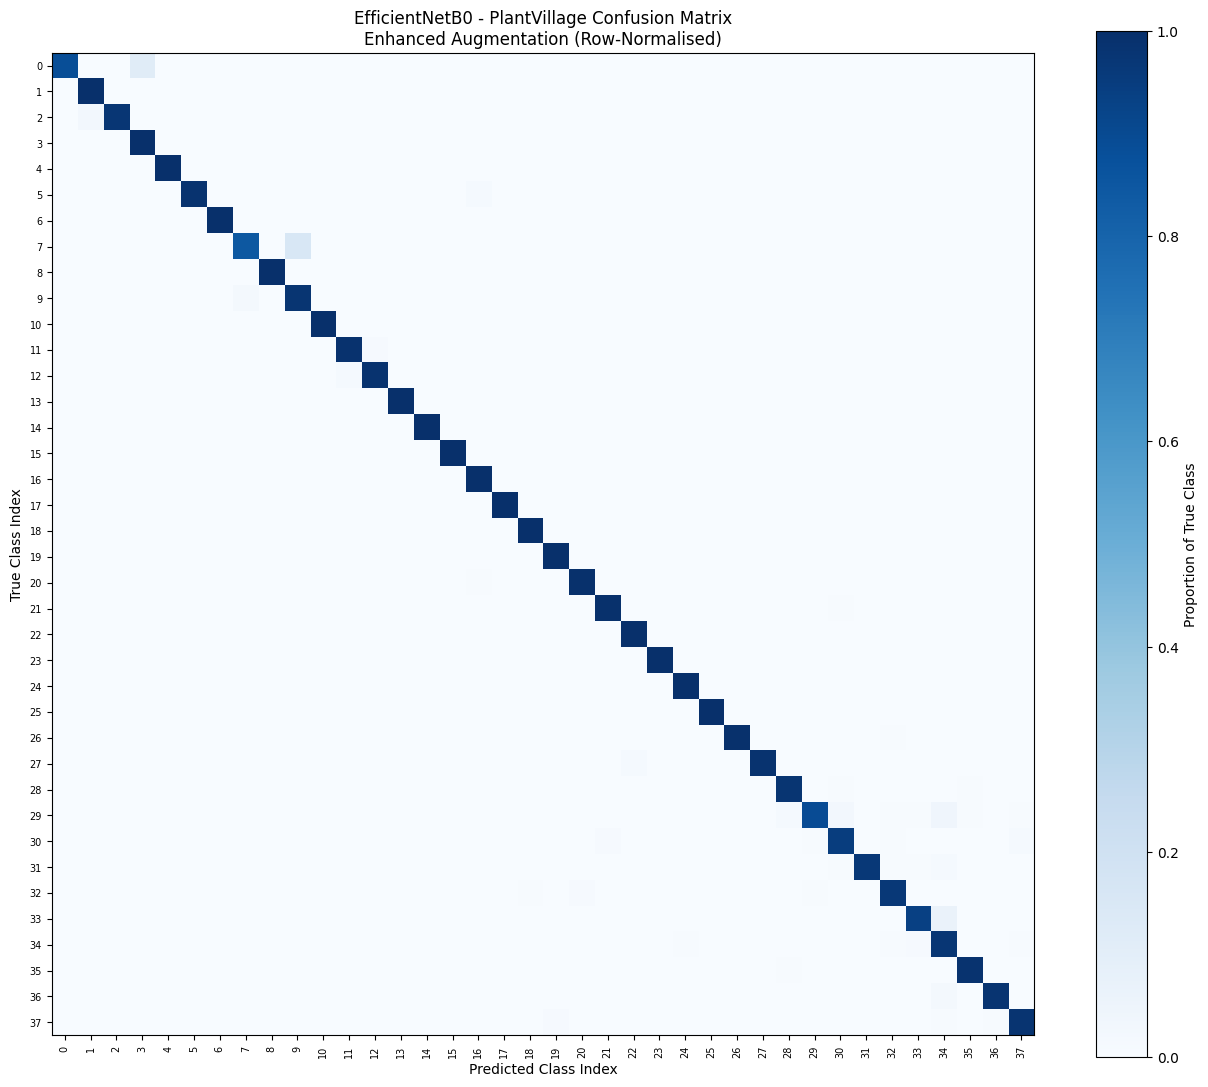


Confusion matrix summary:
Total images       : 8151
Correct predictions: 8023
Incorrect predictions: 128

Top 10 misclassification pairs:
                                        true_class                                    predicted_class  count
     Tomato___Spider_mites Two-spotted_spider_mite                               Tomato___Target_Spot     16
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot                Corn_(maize)___Northern_Leaf_Blight     12
                                Apple___Apple_scab                                    Apple___healthy     11
                             Tomato___Early_blight                               Tomato___Target_Spot      6
                             Tomato___Early_blight                               Tomato___Late_blight      4
                              Tomato___Late_blight                                   Tomato___healthy      4
            Tomato___Tomato_Yellow_Leaf_Curl_Virus                            Tomato___Bacterial_s

In [26]:
# SECTION 5.3: EFFICIENTNETB0 PLANTVILLAGE CONFUSION MATRIX

from sklearn.metrics import confusion_matrix

print("=" * 60)
print("AGROVISION FYP2 - PLANTVILLAGE CONFUSION MATRIX")
print("=" * 60)

# 1. Load saved predictions and class labels
predictions_df = pd.read_csv(pv_predictions_path)
metrics_df = pd.read_csv(pv_metrics_path)

y_true = predictions_df["true_label"].to_numpy()
y_pred = predictions_df["predicted_label"].to_numpy()
class_names = metrics_df.sort_values("class_index")["class_name"].tolist()

assert len(y_true) == len(y_pred) == 8151
assert len(class_names) == NUM_CLASSES

# 2. Calculate confusion matrix
cm = confusion_matrix(
    y_true, y_pred, labels=np.arange(NUM_CLASSES)
)

cm_normalised = cm.astype(float) / cm.sum(axis=1, keepdims=True)

assert cm.shape == (NUM_CLASSES, NUM_CLASSES)
assert cm.sum() == 8151

# 3. Define output paths
pv_cm_path = EFFICIENTNET_PV_DIR / "confusion_matrix.png"
pv_cm_csv_path = EFFICIENTNET_PV_DIR / "confusion_matrix.csv"
pv_confusions_path = EFFICIENTNET_PV_DIR / "top_confusions.csv"

assert not any(p.exists() for p in [
    pv_cm_path, pv_cm_csv_path, pv_confusions_path
])

# 4. Visualise normalised confusion matrix
fig, ax = plt.subplots(figsize=(13, 11))

im = ax.imshow(
    cm_normalised, cmap="Blues", vmin=0, vmax=1
)

ax.set_title(
    "EfficientNetB0 - PlantVillage Confusion Matrix\n"
    "Enhanced Augmentation (Row-Normalised)"
)
ax.set_xlabel("Predicted Class Index")
ax.set_ylabel("True Class Index")
ax.set_xticks(np.arange(NUM_CLASSES))
ax.set_yticks(np.arange(NUM_CLASSES))
ax.tick_params(axis="x", labelrotation=90, labelsize=7)
ax.tick_params(axis="y", labelsize=7)

fig.colorbar(im, ax=ax, label="Proportion of True Class")
plt.tight_layout()
fig.savefig(pv_cm_path, dpi=300, bbox_inches="tight")
plt.show()

# 5. Save complete confusion matrix
pd.DataFrame(
    cm, index=class_names, columns=class_names
).to_csv(pv_cm_csv_path)

# 6. Identify the most frequent misclassifications
confusion_pairs = []

for true_idx, pred_idx in zip(*np.where(cm > 0)):
    if true_idx != pred_idx:
        confusion_pairs.append({
            "true_class": class_names[true_idx],
            "predicted_class": class_names[pred_idx],
            "count": int(cm[true_idx, pred_idx])
        })

top_confusions_df = pd.DataFrame(confusion_pairs).sort_values(
    "count", ascending=False
)

top_confusions_df.to_csv(pv_confusions_path, index=False)

# 7. Display summary
print("\nConfusion matrix summary:")
print("Total images       :", cm.sum())
print("Correct predictions:", np.trace(cm))
print("Incorrect predictions:", cm.sum() - np.trace(cm))

print("\nTop 10 misclassification pairs:")
print(top_confusions_df.head(10).to_string(index=False))

print("\nSaved files:")
print("Confusion matrix image:", pv_cm_path)
print("Confusion matrix CSV  :", pv_cm_csv_path)
print("Misclassification CSV:", pv_confusions_path)

assert pv_cm_path.is_file()
assert pv_cm_csv_path.is_file()
assert pv_confusions_path.is_file()

print("\nPASS: PlantVillage confusion matrix saved.")
print("=" * 60)


In [27]:
# SECTION 5.4: EXTERNAL DATASET READINESS

print("=" * 60)
print("AGROVISION FYP2 - EXTERNAL DATASET READINESS")
print("=" * 60)

# 1. Locate original Phase 2 preparation files
MAPPING_DIR = PROJECT_DIR / "mapping_results"
PLANTDOC_DIR = PROJECT_DIR / "plantdoc_preparation"
FIELDPLANT_DIR = PROJECT_DIR / "fieldplant_preparation"
AUDIT_DIR = PROJECT_DIR / "external_dataset_audit"

plantdoc_inventory_path = PLANTDOC_DIR / "plantdoc_test_inventory.csv"
fieldplant_inventory_path = FIELDPLANT_DIR / "fieldplant_crop_inventory.csv"

required_external_files = [
    plantdoc_inventory_path,
    fieldplant_inventory_path,
    MAPPING_DIR / "plantdoc_final_mapping.csv",
    MAPPING_DIR / "fieldplant_approved_mapping.csv",
    AUDIT_DIR / "plantdoc_exact_overlap.csv",
    AUDIT_DIR / "fieldplant_exact_overlap.csv"
]

missing_files = [str(p) for p in required_external_files if not p.is_file()]
assert not missing_files, "Missing preparation files:\n" + "\n".join(missing_files)

# 2. Load approved external inventories
plantdoc_eval_df = pd.read_csv(plantdoc_inventory_path)
fieldplant_eval_df = pd.read_csv(fieldplant_inventory_path)

assert len(plantdoc_eval_df) == 236
assert len(fieldplant_eval_df) == 504
assert plantdoc_eval_df["filepath"].is_unique
assert fieldplant_eval_df["crop_filepath"].is_unique

plantdoc_eval_df = plantdoc_eval_df.sort_values("filepath").reset_index(drop=True)
fieldplant_eval_df = fieldplant_eval_df.sort_values("crop_filepath").reset_index(drop=True)

# 3. Verify class mapping decisions
plantdoc_mapping = pd.read_csv(MAPPING_DIR / "plantdoc_final_mapping.csv")
fieldplant_mapping = pd.read_csv(MAPPING_DIR / "fieldplant_approved_mapping.csv")

plantdoc_lookup = dict(zip(
    plantdoc_mapping["class_name"],
    plantdoc_mapping["plantvillage_class"]
))
fieldplant_lookup = dict(zip(
    fieldplant_mapping["class_id"].astype(int),
    fieldplant_mapping["plantvillage_class"]
))

assert all(
    plantdoc_lookup.get(row.plantdoc_class) == row.plantvillage_class
    for row in plantdoc_eval_df.itertuples()
)
assert all(
    fieldplant_lookup.get(int(row.fieldplant_class_id)) == row.plantvillage_class
    for row in fieldplant_eval_df.itertuples()
)

for df in [plantdoc_eval_df, fieldplant_eval_df]:
    assert df["plantvillage_class"].isin(class_to_index).all()
    df["class_index"] = df["plantvillage_class"].map(class_to_index).astype("int32")

# 4. Check source image availability
plantdoc_available = plantdoc_eval_df["filepath"].map(
    lambda p: Path(p).is_file()
)
fieldplant_available = fieldplant_eval_df["crop_filepath"].map(
    lambda p: Path(p).is_file()
)

# 5. Display readiness summary
print("\nPreparation files : VERIFIED")
print("Class mappings    : VERIFIED")
print("\nExternal dataset summary:")
print(f"PlantDoc   : {len(plantdoc_eval_df)} images, {plantdoc_eval_df['class_index'].nunique()} classes")
print(f"FieldPlant : {len(fieldplant_eval_df)} crops, {fieldplant_eval_df['class_index'].nunique()} classes")

print("\nImage availability:")
print(f"PlantDoc   : {plantdoc_available.sum()}/{len(plantdoc_eval_df)}")
print(f"FieldPlant : {fieldplant_available.sum()}/{len(fieldplant_eval_df)}")

if not plantdoc_available.all():
    print("\nMissing PlantDoc example:",
          plantdoc_eval_df.loc[~plantdoc_available, "filepath"].iloc[0])

if not fieldplant_available.all():
    print("\nMissing FieldPlant example:",
          fieldplant_eval_df.loc[~fieldplant_available, "crop_filepath"].iloc[0])

print("\nExternal images evaluated: 0")
print("Model retraining performed: No")
print("\nPASS: External inventories and mappings verified.")
print("=" * 60)


AGROVISION FYP2 - EXTERNAL DATASET READINESS

Preparation files : VERIFIED
Class mappings    : VERIFIED

External dataset summary:
PlantDoc   : 236 images, 27 classes
FieldPlant : 504 crops, 4 classes

Image availability:
PlantDoc   : 0/236
FieldPlant : 504/504

Missing PlantDoc example: /content/PlantDoc-Dataset/test/Apple Scab Leaf/052609%20Hartman%20Crabapple%20scab%20single%20leaf.JPG.jpg

External images evaluated: 0
Model retraining performed: No

PASS: External inventories and mappings verified.


In [28]:
# SECTION 5.5: RESTORE PLANTDOC DATASET

import subprocess

print("=" * 60)
print("AGROVISION FYP2 - PLANTDOC DATASET RESTORATION")
print("=" * 60)

# 1. Restore the original PlantDoc repository
plantdoc_root = Path("/content/PlantDoc-Dataset")
plantdoc_repo = "https://github.com/pratikkayal/PlantDoc-Dataset.git"

if plantdoc_root.is_dir():
    print("\nPlantDoc repository already exists.")
else:
    assert not plantdoc_root.exists(), "PlantDoc path is not a directory."
    print("\nRestoring original PlantDoc repository...")
    subprocess.run(
        ["git", "clone", "--depth", "1", plantdoc_repo, str(plantdoc_root)],
        check=True
    )

# 2. Verify approved PlantDoc image paths
plantdoc_available = plantdoc_eval_df["filepath"].map(
    lambda p: Path(p).is_file()
)
fieldplant_available = fieldplant_eval_df["crop_filepath"].map(
    lambda p: Path(p).is_file()
)

print("\nExternal image availability:")
print(f"PlantDoc   : {plantdoc_available.sum()}/{len(plantdoc_eval_df)}")
print(f"FieldPlant : {fieldplant_available.sum()}/{len(fieldplant_eval_df)}")

# 3. Verify all required images
missing_plantdoc = plantdoc_eval_df.loc[
    ~plantdoc_available, "filepath"
].tolist()

assert not missing_plantdoc, (
    "Missing PlantDoc images:\n" + "\n".join(missing_plantdoc[:5])
)
assert fieldplant_available.all()
assert len(plantdoc_eval_df) == 236
assert len(fieldplant_eval_df) == 504
assert plantdoc_eval_df["class_index"].nunique() == 27
assert fieldplant_eval_df["class_index"].nunique() == 4

print("\nPreparation inventories : VERIFIED")
print("Approved class mappings: PRESERVED")
print("External image files   : ALL AVAILABLE")
print("Model training         : NOT PERFORMED")
print("External evaluation    : NOT STARTED")

print("\n" + "=" * 60)
print("PASS: EXTERNAL DATASETS READY FOR EVALUATION")
print("=" * 60)


AGROVISION FYP2 - PLANTDOC DATASET RESTORATION

Restoring original PlantDoc repository...

External image availability:
PlantDoc   : 236/236
FieldPlant : 504/504

Preparation inventories : VERIFIED
Approved class mappings: PRESERVED
External image files   : ALL AVAILABLE
Model training         : NOT PERFORMED
External evaluation    : NOT STARTED

PASS: EXTERNAL DATASETS READY FOR EVALUATION


In [29]:
# SECTION 5.6: EXTERNAL EVALUATION DATA PIPELINES

import math

print("=" * 60)
print("AGROVISION FYP2 - EXTERNAL EVALUATION PIPELINES")
print("=" * 60)

# 1. Define evaluation-only image preprocessing
def load_external_evaluation_image(filepath, label):
    image_bytes = tf.io.read_file(filepath)
    image = tf.io.decode_image(
        image_bytes, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(
        image, IMAGE_SIZE, method="bilinear", antialias=False
    )
    image = tf.cast(image, tf.float32)
    image.set_shape([IMAGE_SIZE[0], IMAGE_SIZE[1], 3])
    return image, tf.cast(label, tf.int32)

# 2. Define approved external datasets
external_sources = {
    "PlantDoc": {
        "frame": plantdoc_eval_df,
        "path_column": "filepath",
        "expected_images": 236,
        "expected_classes": 27
    },
    "FieldPlant": {
        "frame": fieldplant_eval_df,
        "path_column": "crop_filepath",
        "expected_images": 504,
        "expected_classes": 4
    }
}

# 3. Construct deterministic evaluation pipelines
external_datasets = {}

for dataset_name, config in external_sources.items():
    frame = config["frame"]
    filepaths = frame[config["path_column"]].astype(str).to_numpy()
    true_labels = frame["class_index"].to_numpy(dtype=np.int32)
    true_classes = frame["plantvillage_class"].astype(str).to_numpy()

    source_paths = (
        frame["source_image_filepath"].astype(str).to_numpy()
        if dataset_name == "FieldPlant"
        else filepaths.copy()
    )

    assert len(filepaths) == config["expected_images"]
    assert len(np.unique(true_labels)) == config["expected_classes"]
    assert len(np.unique(filepaths)) == len(filepaths)
    assert all(Path(p).is_file() for p in filepaths)
    assert np.array_equal(
        true_labels,
        np.array([class_to_index[c] for c in true_classes])
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (filepaths, true_labels)
    )
    dataset = dataset.map(
        load_external_evaluation_image,
        num_parallel_calls=2,
        deterministic=True
    )
    dataset = dataset.batch(BATCH_SIZE).prefetch(1)

    expected_batches = math.ceil(len(filepaths) / BATCH_SIZE)
    assert int(tf.data.experimental.cardinality(dataset).numpy()) == expected_batches

    # Verify a sample image
    sample_images, sample_labels = next(iter(dataset))
    assert sample_images.shape[1:] == (160, 160, 3)
    assert sample_images.dtype == tf.float32
    tf.debugging.assert_all_finite(sample_images, "Invalid image values")
    assert float(tf.reduce_min(sample_images)) >= 0
    assert float(tf.reduce_max(sample_images)) <= 255

    external_datasets[dataset_name] = {
        "dataset": dataset,
        "filepaths": filepaths,
        "source_paths": source_paths,
        "true_classes": true_classes,
        "true_labels": true_labels
    }

    print(f"\n{dataset_name}:")
    print("Images          :", len(filepaths))
    print("Classes         :", len(np.unique(true_labels)))
    print("Batches         :", expected_batches)
    print("Sample shape    :", sample_images.shape)
    print("Image decoding  : VERIFIED")

# 4. Verify both pipelines
assert len(external_datasets) == 2

print("\nPreprocessing:")
print("Image size       :", IMAGE_SIZE)
print("Colour channels  : RGB")
print("Pixel range      : [0, 255]")
print("Shuffling        : Disabled")
print("Augmentation     : Disabled during evaluation")
print("Model outputs    :", NUM_CLASSES, "classes")

print("\nExternal predictions performed: 0")
print("Model retraining performed    : No")

print("\n" + "=" * 60)
print("PASS: EXTERNAL EVALUATION PIPELINES READY")
print("=" * 60)


AGROVISION FYP2 - EXTERNAL EVALUATION PIPELINES

PlantDoc:
Images          : 236
Classes         : 27
Batches         : 8
Sample shape    : (32, 160, 160, 3)
Image decoding  : VERIFIED

FieldPlant:
Images          : 504
Classes         : 4
Batches         : 16
Sample shape    : (32, 160, 160, 3)
Image decoding  : VERIFIED

Preprocessing:
Image size       : (160, 160)
Colour channels  : RGB
Pixel range      : [0, 255]
Shuffling        : Disabled
Augmentation     : Disabled during evaluation
Model outputs    : 38 classes

External predictions performed: 0
Model retraining performed    : No

PASS: EXTERNAL EVALUATION PIPELINES READY


In [30]:
# SECTION 5.7: EFFICIENTNETB0 EXTERNAL INFERENCE

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 EXTERNAL INFERENCE")
print("=" * 60)

# 1. Prepare output directory
EFFICIENTNET_EXTERNAL_DIR = EFFICIENTNET_EVAL_DIR / "external"
EFFICIENTNET_EXTERNAL_DIR.mkdir(parents=True, exist_ok=True)

assert efficientnetb0_stage2_checkpoint.is_file()
assert efficientnetb0_final_model.output_shape == (None, NUM_CLASSES)

# 2. Verify saved prediction files
def verify_external_prediction_file(path, data):
    with np.load(path, allow_pickle=False) as saved:
        probs = saved["probabilities"]
        predicted = saved["predicted_labels"]
        true_labels = data["true_labels"]

        assert probs.shape == (len(true_labels), NUM_CLASSES)
        assert np.array_equal(saved["true_labels"], true_labels)
        assert np.array_equal(predicted, np.argmax(probs, axis=1))
        assert np.array_equal(saved["filepaths"], data["filepaths"])
        assert np.array_equal(saved["true_classes"], data["true_classes"])
        assert np.array_equal(saved["source_image_filepaths"], data["source_paths"])
        assert np.isfinite(probs).all()
        assert np.allclose(probs.sum(axis=1), 1.0, atol=1e-3)

# 3. Generate or verify predictions
efficientnetb0_external_prediction_paths = {}

for dataset_name, data in external_datasets.items():
    output_path = EFFICIENTNET_EXTERNAL_DIR / f"{dataset_name}_predictions.npz"
    temporary_path = EFFICIENTNET_EXTERNAL_DIR / f"{dataset_name}_predictions.partial.npz"

    print(f"\nDataset: {dataset_name}")
    print("Images :", len(data["true_labels"]))

    if output_path.exists():
        verify_external_prediction_file(output_path, data)
        print("Existing predictions verified.")

    elif temporary_path.exists():
        verify_external_prediction_file(temporary_path, data)
        temporary_path.replace(output_path)
        print("Previous predictions recovered and verified.")

    else:
        probabilities = efficientnetb0_final_model.predict(
            data["dataset"], verbose=1
        ).astype(np.float32)

        predicted_labels = np.argmax(
            probabilities, axis=1
        ).astype(np.int32)

        assert probabilities.shape == (
            len(data["true_labels"]), NUM_CLASSES
        )

        np.savez_compressed(
            temporary_path,
            true_labels=np.asarray(data["true_labels"], dtype=np.int32),
            true_classes=np.asarray(data["true_classes"], dtype=np.str_),
            predicted_labels=predicted_labels,
            probabilities=probabilities,
            filepaths=np.asarray(data["filepaths"], dtype=np.str_),
            source_image_filepaths=np.asarray(data["source_paths"], dtype=np.str_)
        )

        verify_external_prediction_file(temporary_path, data)
        temporary_path.replace(output_path)
        print("New predictions saved and verified.")

    efficientnetb0_external_prediction_paths[dataset_name] = output_path
    print("Saved to:", output_path)

# 4. Final verification
assert len(efficientnetb0_external_prediction_paths) == 2
assert all(
    path.is_file()
    for path in efficientnetb0_external_prediction_paths.values()
)

print("\n" + "=" * 60)
print("PASS: EFFICIENTNETB0 EXTERNAL INFERENCE COMPLETED")
print("=" * 60)
print("PlantDoc predictions  : 236")
print("FieldPlant predictions: 504")
print("Output classes        : 38")
print("Predictions saved     : Yes")
print("Model retraining      : No")


AGROVISION FYP2 - EFFICIENTNETB0 EXTERNAL INFERENCE

Dataset: PlantDoc
Images : 236
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 445ms/step
New predictions saved and verified.
Saved to: /content/drive/MyDrive/AgroVision_FYP2/augmentation_retraining/enhanced_v1/EfficientNetB0/evaluation/external/PlantDoc_predictions.npz

Dataset: FieldPlant
Images : 504
16/16 ━━━━━━━━━━━━━━━━━━━━ 172s 11s/step
New predictions saved and verified.
Saved to: /content/drive/MyDrive/AgroVision_FYP2/augmentation_retraining/enhanced_v1/EfficientNetB0/evaluation/external/FieldPlant_predictions.npz

PASS: EFFICIENTNETB0 EXTERNAL INFERENCE COMPLETED
PlantDoc predictions  : 236
FieldPlant predictions: 504
Output classes        : 38
Predictions saved     : Yes
Model retraining      : No


In [31]:
# SECTION 5.8: EFFICIENTNETB0 EXTERNAL CLASSIFICATION METRICS

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 EXTERNAL METRICS")
print("=" * 60)

# 1. Locate saved prediction files
external_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/"
    "augmentation_retraining/enhanced_v1/"
    "EfficientNetB0/evaluation/external"
)

dataset_config = {
    "PlantDoc": (236, 27),
    "FieldPlant": (504, 4)
}

results = []

# 2. Calculate evaluation metrics
for dataset_name, (expected_images, expected_classes) in dataset_config.items():
    prediction_path = external_dir / f"{dataset_name}_predictions.npz"
    assert prediction_path.is_file(), f"Missing file: {prediction_path}"

    with np.load(prediction_path, allow_pickle=False) as saved:
        y_true = saved["true_labels"].copy()
        y_pred = saved["predicted_labels"].copy()
        probabilities = saved["probabilities"].copy()

    represented_classes = np.unique(y_true)

    assert len(y_true) == len(y_pred) == expected_images
    assert len(represented_classes) == expected_classes
    assert probabilities.shape == (expected_images, 38)
    assert np.array_equal(y_pred, np.argmax(probabilities, axis=1))
    assert np.isfinite(probabilities).all()

    accuracy = accuracy_score(y_true, y_pred)

    weighted_precision, weighted_recall, weighted_f1, _ = (
        precision_recall_fscore_support(
            y_true, y_pred,
            labels=represented_classes,
            average="weighted",
            zero_division=0
        )
    )

    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true, y_pred,
            labels=represented_classes,
            average="macro",
            zero_division=0
        )
    )

    correct = int(np.sum(y_true == y_pred))
    incorrect = expected_images - correct
    outside_count = int(np.sum(~np.isin(y_pred, represented_classes)))

    assert np.isclose(weighted_recall, accuracy)
    assert outside_count <= incorrect

    results.append({
        "dataset": f"Cropped-{dataset_name}",
        "model": "EfficientNetB0",
        "test_images": expected_images,
        "represented_classes": expected_classes,
        "correct_predictions": correct,
        "incorrect_predictions": incorrect,
        "accuracy": accuracy,
        "weighted_precision": weighted_precision,
        "weighted_recall": weighted_recall,
        "weighted_f1": weighted_f1,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "predictions_outside_coverage": outside_count,
        "outside_coverage_percentage": outside_count / expected_images * 100
    })

    print(f"\n{dataset_name} results:")
    print(f"Images             : {expected_images}")
    print(f"Represented classes: {expected_classes}")
    print(f"Accuracy           : {accuracy:.4%}")
    print(f"Weighted F1-score  : {weighted_f1:.4%}")
    print(f"Macro F1-score     : {macro_f1:.4%}")
    print(f"Correct predictions: {correct}")
    print(f"Incorrect predictions: {incorrect}")
    print(f"Outside coverage   : {outside_count} ({outside_count / expected_images:.2%})")

# 3. Save results
external_metrics_df = pd.DataFrame(results)
external_metrics_path = external_dir / "external_dataset_metrics.csv"

if external_metrics_path.exists():
    saved_df = pd.read_csv(external_metrics_path)
    pd.testing.assert_frame_equal(
        saved_df, external_metrics_df,
        check_exact=False, atol=1e-8, rtol=1e-8
    )
    print("\nExisting metrics file verified.")
else:
    external_metrics_df.to_csv(
        external_metrics_path, index=False, float_format="%.12f"
    )
    print("\nExternal metrics saved.")

assert external_metrics_path.is_file()

print("\n" + "=" * 60)
print("PASS: EFFICIENTNETB0 EXTERNAL METRICS COMPLETED")
print("=" * 60)
print("Saved to:", external_metrics_path)
print("Additional inference: No")
print("Model retraining  : No")


AGROVISION FYP2 - EFFICIENTNETB0 EXTERNAL METRICS

PlantDoc results:
Images             : 236
Represented classes: 27
Accuracy           : 27.1186%
Weighted F1-score  : 24.5873%
Macro F1-score     : 25.2116%
Correct predictions: 64
Incorrect predictions: 172
Outside coverage   : 33 (13.98%)

FieldPlant results:
Images             : 504
Represented classes: 4
Accuracy           : 31.7460%
Weighted F1-score  : 37.1626%
Macro F1-score     : 38.6500%
Correct predictions: 160
Incorrect predictions: 344
Outside coverage   : 312 (61.90%)

External metrics saved.

PASS: EFFICIENTNETB0 EXTERNAL METRICS COMPLETED
Saved to: /content/drive/MyDrive/AgroVision_FYP2/augmentation_retraining/enhanced_v1/EfficientNetB0/evaluation/external/external_dataset_metrics.csv
Additional inference: No
Model retraining  : No


In [32]:
# SECTION 5.9: EFFICIENTNETB0 EXTERNAL ERROR ANALYSIS

from collections import Counter

print("=" * 60)
print("AGROVISION FYP2 - EXTERNAL ERROR ANALYSIS")
print("=" * 60)

index_to_class = {v: k for k, v in class_to_index.items()}
assert len(index_to_class) == NUM_CLASSES

class_records = []
confusion_records = []

for dataset_name in ["PlantDoc", "FieldPlant"]:
    path = external_dir / f"{dataset_name}_predictions.npz"

    with np.load(path, allow_pickle=False) as saved:
        y_true = saved["true_labels"].copy()
        y_pred = saved["predicted_labels"].copy()
        source_paths = saved["source_image_filepaths"].copy()

    represented = np.unique(y_true)
    outside = ~np.isin(y_pred, represented)

    # Calculate recall and out-of-coverage errors per class
    dataset_rows = []

    for class_idx in represented:
        mask = y_true == class_idx
        support = int(mask.sum())
        correct = int((y_pred[mask] == class_idx).sum())

        record = {
            "dataset": dataset_name,
            "class_name": index_to_class[int(class_idx)],
            "support": support,
            "correct": correct,
            "recall": correct / support,
            "outside_coverage_errors": int(outside[mask].sum())
        }

        class_records.append(record)
        dataset_rows.append(record)

    # Identify common incorrect prediction pairs
    mistakes = Counter(
        (int(t), int(p))
        for t, p in zip(y_true, y_pred)
        if t != p
    )

    for (true_idx, pred_idx), count in mistakes.items():
        confusion_records.append({
            "dataset": dataset_name,
            "true_class": index_to_class[true_idx],
            "predicted_class": index_to_class[pred_idx],
            "count": count
        })

    print(f"\n{dataset_name}:")
    print("Images              :", len(y_true))
    print("Source photographs  :", len(np.unique(source_paths)))
    print("Correct predictions :", int((y_true == y_pred).sum()))
    print("Outside coverage    :", int(outside.sum()))

    print("\nFive classes with lowest recall:")
    print(
        pd.DataFrame(dataset_rows)
        .sort_values(["recall", "support"], ascending=[True, False])
        .head(5)[["class_name", "support", "recall", "outside_coverage_errors"]]
        .to_string(index=False)
    )

    print("\nMost frequent misclassifications:")
    for (true_idx, pred_idx), count in mistakes.most_common(5):
        print(f"{count:3d} | {index_to_class[true_idx]} -> {index_to_class[pred_idx]}")

# Save detailed analysis
external_class_metrics_df = pd.DataFrame(class_records)
external_confusions_df = pd.DataFrame(confusion_records)

external_class_metrics_path = external_dir / "external_per_class_metrics.csv"
external_confusions_path = external_dir / "external_confusion_pairs.csv"

assert not external_class_metrics_path.exists()
assert not external_confusions_path.exists()

external_class_metrics_df.to_csv(
    external_class_metrics_path, index=False
)
external_confusions_df.to_csv(
    external_confusions_path, index=False
)

assert len(external_class_metrics_df) == 31
assert external_class_metrics_path.is_file()
assert external_confusions_path.is_file()

print("\nSaved files:")
print(external_class_metrics_path)
print(external_confusions_path)

print("\nPASS: External error analysis completed.")
print("=" * 60)


AGROVISION FYP2 - EXTERNAL ERROR ANALYSIS

PlantDoc:
Images              : 236
Source photographs  : 236
Correct predictions : 64
Outside coverage    : 33

Five classes with lowest recall:
                       class_name  support  recall  outside_coverage_errors
               Apple___Apple_scab       10     0.0                        3
         Apple___Cedar_apple_rust       10     0.0                        3
Cherry_(including_sour)___healthy       10     0.0                        1
     Tomato___Tomato_mosaic_virus       10     0.0                        2
          Tomato___Bacterial_spot        9     0.0                        1

Most frequent misclassifications:
  5 | Apple___Cedar_apple_rust -> Pepper,_bell___Bacterial_spot
  5 | Cherry_(including_sour)___healthy -> Apple___healthy
  5 | Potato___Late_blight -> Tomato___Late_blight
  5 | Grape___healthy -> Squash___Powdery_mildew
  4 | Corn_(maize)___Northern_Leaf_Blight -> Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot



In [33]:
# SECTION 5.10: EFFICIENTNETB0 FINAL EXPERIMENT COMPARISON

import json
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 60)
print("AGROVISION FYP2 - EFFICIENTNETB0 FINAL COMPARISON")
print("=" * 60)

# 1. Define original and enhanced evaluation files
original_dir = PROJECT_DIR / "model_evaluation"
enhanced_dir = EFFICIENTNET_DIR / "evaluation"

original_pv_path = original_dir / "plantvillage_test/plantvillage_test_metrics.csv"
original_class_path = original_dir / "plantvillage_test/plantvillage_per_class_metrics.csv"
original_ext_path = original_dir / "external_evaluation/external_dataset_metrics.csv"

enhanced_pv_path = enhanced_dir / "plantvillage/test_summary.json"
enhanced_class_path = enhanced_dir / "plantvillage/per_class_metrics.csv"
enhanced_ext_path = enhanced_dir / "external/external_dataset_metrics.csv"

source_paths = [
    original_pv_path, original_class_path, original_ext_path,
    enhanced_pv_path, enhanced_class_path, enhanced_ext_path
]
assert all(path.is_file() for path in source_paths), "Missing evaluation files."

# 2. Load original results
original_pv = pd.read_csv(original_pv_path).set_index("model").loc["EfficientNetB0"]
original_classes = pd.read_csv(original_class_path)
original_classes = original_classes.query("model == 'EfficientNetB0'")
original_ext = pd.read_csv(original_ext_path).query(
    "model == 'EfficientNetB0'"
).set_index("dataset")

# 3. Load enhanced results
with open(enhanced_pv_path) as f:
    enhanced_pv = json.load(f)

enhanced_classes = pd.read_csv(enhanced_class_path)
enhanced_ext = pd.read_csv(enhanced_ext_path).set_index("dataset")

assert len(original_classes) == len(enhanced_classes) == 38
assert len(original_ext) == len(enhanced_ext) == 2

# 4. Prepare comparison values
comparison_sources = {
    "PlantVillage": (
        {
            "accuracy": float(original_pv["accuracy"]),
            "weighted_f1": float(original_pv["weighted_f1"]),
            "macro_f1": original_classes["f1_score"].mean()
        },
        {
            "accuracy": float(enhanced_pv["test_accuracy"]),
            "weighted_f1": np.average(
                enhanced_classes["f1_score"],
                weights=enhanced_classes["support"]
            ),
            "macro_f1": enhanced_classes["f1_score"].mean()
        }
    )
}

for dataset in ["Cropped-PlantDoc", "Cropped-FieldPlant"]:
    comparison_sources[dataset] = (
        original_ext.loc[dataset],
        enhanced_ext.loc[dataset]
    )

# 5. Calculate changes in percentage points
records = []

for dataset, (original, enhanced) in comparison_sources.items():
    for metric in ["accuracy", "weighted_f1", "macro_f1"]:
        old_value = float(original[metric]) * 100
        new_value = float(enhanced[metric]) * 100

        records.append({
            "dataset": dataset,
            "metric": metric,
            "original_pct": old_value,
            "enhanced_pct": new_value,
            "change_pp": new_value - old_value
        })

comparison_df = pd.DataFrame(records)

# 6. Save final comparison
comparison_path = enhanced_dir / "original_vs_enhanced_comparison.csv"

if comparison_path.exists():
    saved_df = pd.read_csv(comparison_path)
    pd.testing.assert_frame_equal(
        saved_df, comparison_df,
        check_exact=False, atol=1e-8, rtol=1e-8
    )
else:
    comparison_df.to_csv(comparison_path, index=False, float_format="%.12f")

# 7. Display final comparison
display_df = comparison_df.copy()
for column in ["original_pct", "enhanced_pct", "change_pp"]:
    display_df[column] = display_df[column].round(2)

print("\nOriginal vs enhanced augmentation:")
print(display_df.to_string(index=False))

print("\nExternal prediction coverage:")
for dataset in ["Cropped-PlantDoc", "Cropped-FieldPlant"]:
    old_count = int(original_ext.loc[dataset, "predictions_outside_coverage"])
    new_count = int(enhanced_ext.loc[dataset, "predictions_outside_coverage"])
    print(f"{dataset}: {old_count} -> {new_count} ({new_count - old_count:+d})")

# 8. Confirm final experiment files
assert efficientnetb0_stage1_checkpoint.is_file()
assert efficientnetb0_stage2_checkpoint.is_file()
assert comparison_path.is_file()

print("\nStage 1 checkpoint : VERIFIED")
print("Stage 2 checkpoint : VERIFIED")
print("Evaluation results : VERIFIED")
print("Comparison file    :", comparison_path)

print("\n" + "=" * 60)
print("PASS: EFFICIENTNETB0 EXPERIMENT COMPARISON COMPLETED")
print("=" * 60)


AGROVISION FYP2 - EFFICIENTNETB0 FINAL COMPARISON

Original vs enhanced augmentation:
           dataset      metric  original_pct  enhanced_pct  change_pp
      PlantVillage    accuracy         98.52         98.43      -0.09
      PlantVillage weighted_f1         98.52         98.43      -0.09
      PlantVillage    macro_f1         98.25         98.03      -0.22
  Cropped-PlantDoc    accuracy         27.12         27.12       0.00
  Cropped-PlantDoc weighted_f1         25.52         24.59      -0.94
  Cropped-PlantDoc    macro_f1         25.86         25.21      -0.64
Cropped-FieldPlant    accuracy         27.78         31.75       3.97
Cropped-FieldPlant weighted_f1         34.58         37.16       2.58
Cropped-FieldPlant    macro_f1         36.42         38.65       2.23

External prediction coverage:
Cropped-PlantDoc: 34 -> 33 (-1)
Cropped-FieldPlant: 351 -> 312 (-39)

Stage 1 checkpoint : VERIFIED
Stage 2 checkpoint : VERIFIED
Evaluation results : VERIFIED
Comparison file    : /c